<a href="https://colab.research.google.com/github/usumakikai8-bot/DNN/blob/main/dnn8_grid_dnn_section_selector_alm_fixed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DNN8-ALM — Augmented-Lagrangian structural-monotonicity constraints for the DNN8 grid section selector (PyTorch)

This notebook **extends** the existing DNN8 grid-based steel-section selector; the model, parser, catalog handling, grid encoding,
fixed-range normalisation, fixed `train/ val/ test` split and the masked cross-entropy are kept **unchanged**
(the corresponding cells are copied verbatim from `dnn8-grid-dnn-section-selector-normalization.ipynb`). The ALM stands for the Augmented Lagrangian Method.

What is new (all in clearly marked cells below):

* differentiable **expected physical dimensions** $\hat H=\sum_k p_kH_k$ (beams) and $\hat D=\sum_k p_kD_k$ (columns),
* **pair generation** (two building conditions that differ in exactly one parameter, compared at corresponding member positions),
* four independently switchable monotonicity constraints (beam H vs X-span, beam H vs load, column D vs load, column D vs story height),
* the **augmented-Lagrangian** loss, multiplier update $\lambda\leftarrow\max(0,\lambda+\rho g)$ and penalty update,
* five ablation experiments **A–E** (baseline, beam-span, load, column-height, combined), constraint diagnostics, a teacher-data audit of the priors,
  checkpoint save/load, and the seven acceptance tests of the specification.

```
dnn8/
    dnn8-grid-dnn-section-selector-alm.ipynb      <- this notebook
    dataset/  catalog/  train/  val/  test/
    dnn-results/
```
**Usage:** run the cells top to bottom (Colab). Set `RUN_EXPERIMENTS` / `QUICK_EPOCHS` in the *ALM configuration* cell to run a subset or a smoke test first.


## Import modules and mount google drive

In [1]:
import os, re, csv, glob, sys, random
from collections import defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F_
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from google.colab import drive, files

drive.mount('/content/drive')

Mounted at /content/drive


## Set the current working directory.

In [2]:
import os

# Check the current working directory
print("Before:", os.getcwd())

# Change to a new directory (absolute or relative path)
os.chdir("/content/drive/MyDrive/research/dnn8")

# Verify the change
print("After:", os.getcwd())

Before: /content
After: /content/drive/MyDrive/research/dnn8


## Set paths

In [3]:
# ============================================================
# Project / dataset configuration
# ============================================================
PROJECT_ROOT = Path.cwd()

DATASET_CANDIDATES = [
    Path('/content/drive/MyDrive/research/dnn8/dataset'),
]
DATASET_ROOT = next((p for p in DATASET_CANDIDATES if p.is_dir()), DATASET_CANDIDATES[0])

CATALOG_ROOT = DATASET_ROOT / 'catalog'
H_CATALOG_FILE = 'beam-narrow-medium-catalog.csv'
BOX_CATALOG_FILE = 'column-all-bcr-catalog.csv'
CATALOG_BEAM_CSV = CATALOG_ROOT / H_CATALOG_FILE
CATALOG_COLUMN_CSV = CATALOG_ROOT / BOX_CATALOG_FILE

SPLITS = ('train', 'val', 'test')

# Set appropriate output paths.
OUTPUT_DIR = PROJECT_ROOT / 'dnn-alm-results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(f'Dataset not found: {DATASET_ROOT}')
for split in SPLITS:
    if not (DATASET_ROOT / split).is_dir():
        raise FileNotFoundError(f'Missing split directory: {DATASET_ROOT / split}')
if not CATALOG_ROOT.is_dir():
    raise FileNotFoundError(f'Missing catalog directory: {CATALOG_ROOT}')
for name in (H_CATALOG_FILE, BOX_CATALOG_FILE):
    if not (CATALOG_ROOT / name).is_file():
        raise FileNotFoundError(f'Missing catalog: {CATALOG_ROOT / name}')

print('DATASET_ROOT =', DATASET_ROOT)
print('CATALOG_ROOT =', CATALOG_ROOT)
print('OUTPUT_DIR =', OUTPUT_DIR)

DATASET_ROOT = /content/drive/MyDrive/research/dnn8/dataset
CATALOG_ROOT = /content/drive/MyDrive/research/dnn8/dataset/catalog
OUTPUT_DIR = /content/drive/MyDrive/research/dnn8/dnn-alm-results


## Settings

In [4]:
# ============================================================
# Training configurations
# ============================================================
dnn = 'DNN8-alm'

SEED          = 42
EPOCHS        = 400
PATIENCE      = 40            # early stopping on validation loss
BATCH_SIZE    = 32
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-4
HIDDEN        = (512, 512, 512)    # widths of the fully connected hidden layers
DROPOUT       = 0.1

# Only catalog rows with enabled == 1 are used (as DNN output classes and as teacher labels).
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

CHECKPOINT_PATH       = OUTPUT_DIR / 'best-dnn8-grid.pt'
PREDICTIONS_PATH      = OUTPUT_DIR / 'dnn8-test-predictions.csv'
TRAINING_HISTORY_PATH = OUTPUT_DIR / 'dnn8-training-history.csv'
RESULTS_TEXT_PATH     = OUTPUT_DIR / f'{dnn}-results.txt'

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_everything()

print('DEVICE =', DEVICE)
print('CHECKPOINT_PATH =', CHECKPOINT_PATH)
print('PREDICTIONS_PATH =', PREDICTIONS_PATH)
print('TRAINING_HISTORY_PATH =', TRAINING_HISTORY_PATH)
print('RESULTS_TEXT_PATH =', RESULTS_TEXT_PATH)

DEVICE = cpu
CHECKPOINT_PATH = /content/drive/MyDrive/research/dnn8/dnn-alm-results/best-dnn8-grid.pt
PREDICTIONS_PATH = /content/drive/MyDrive/research/dnn8/dnn-alm-results/dnn8-test-predictions.csv
TRAINING_HISTORY_PATH = /content/drive/MyDrive/research/dnn8/dnn-alm-results/dnn8-training-history.csv
RESULTS_TEXT_PATH = /content/drive/MyDrive/research/dnn8/dnn-alm-results/DNN8-alm-results.txt


## Catalog loading

In [5]:
# Catalog loading
def read_rows(path):
    """Read a CSV into a list of rows (list of strings). Handles UTF-8 (with BOM) and Shift-JIS."""
    for enc in ("utf-8-sig", "cp932"):
        try:
            with open(path, encoding=enc, newline="") as f:
                return list(csv.reader(f))
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Cannot decode {path}")

def norm_name(s):
    """Normalise a section name so that '□-150x150x6x15' and 'B-150x150x6x15' give the same key."""
    s = s.strip().replace("×", "x").replace("－", "-").replace(" ", "").lower()
    return re.sub(r"^[^\-]*-", "", s)          # drop the shape prefix (H-, B-, □-, ...)

class DisabledSectionError(KeyError):
    """Raised when a teacher section exists in the catalog but is flagged enabled == 0."""

class Catalog:
    """Section catalog. The class index k of the DNN output corresponds to row k of the catalog."""
    def __init__(self, path, size_col):
        for enc in ("utf-8-sig", "cp932"):
            try:
                df_all = pd.read_csv(path, encoding=enc); break
            except UnicodeDecodeError:
                continue
        # Only rows with enabled == 1 are processed. The DNN class index k is the row of this filtered catalog.
        self.df = df_all[df_all["enabled"].astype(int) == 1].reset_index(drop=True)
        if len(self.df) == 0:
            raise ValueError(f"No rows with enabled == 1 in {path}")
        self.disabled_keys = {norm_name(n) for n in df_all.loc[df_all["enabled"].astype(int) != 1, "name"].astype(str)}
        self.n       = len(self.df)
        self.ids     = self.df["id"].to_numpy(dtype=int)               # component IDs (output of the model)
        self.names   = self.df["name"].astype(str).to_numpy()
        self.enabled = self.df["enabled"].to_numpy(dtype=int)
        self.mass    = self.df["mass_kg_m"].to_numpy(dtype=float)      # kg/m, used for weight estimates
        self.size    = self.df[size_col].to_numpy(dtype=float)         # D_mm (columns) or H_mm (beams)
        self.key2idx = {norm_name(n): k for k, n in enumerate(self.names)}
        if len(self.key2idx) != self.n:
            raise ValueError(f"Duplicate section names in {path}")

    def index_of(self, name):
        key = norm_name(name)
        if key not in self.key2idx:
            if key in self.disabled_keys:
                raise DisabledSectionError(f"Section '{name}' is disabled (enabled=0) in the catalog")
            raise KeyError(f"Section '{name}' is not in the catalog")
        return self.key2idx[key]

cat_col  = Catalog(CATALOG_COLUMN_CSV, "D_mm")
cat_beam = Catalog(CATALOG_BEAM_CSV,   "H_mm")
print(f"Column catalog: {cat_col.n} enabled sections (enabled=1 only)")
print(f"Beam catalog  : {cat_beam.n} enabled sections (enabled=1 only)")

Column catalog: 63 enabled sections (enabled=1 only)
Beam catalog  : 27 enabled sections (enabled=1 only)


## Model-CSV parser

In [6]:
# Model-CSV parser
# The model CSV is a sequence of blocks:  "name=<block name>"  followed by rows until a blank row.
# Inside a block, an optional "<data>" row separates the header from the data rows.

def parse_sections(rows):
    secs, cur = {}, None
    for row in rows:
        if row and row[0].startswith("name="):
            cur = row[0][len("name="):].strip()
            secs.setdefault(cur, [])
        elif cur is not None:
            if not any(c.strip() for c in row):
                cur = None                      # blank row ends the block
            else:
                secs[cur].append(row)
    return secs

def table(sec_rows):
    """Return (header, data_rows) of a block."""
    for k, r in enumerate(sec_rows):
        if r and r[0].strip() == "<data>":
            return sec_rows[k - 1], sec_rows[k + 1:]
    return sec_rows[0], sec_rows[1:]

def story_of_column_label(label):
    """Column row label '1FL','2FL',... -> story number (1 = lowest story)."""
    m = re.match(r"(\d+)", label.strip())
    if not m:
        raise ValueError(f"Unknown column floor label: {label}")
    return int(m.group(1))

def story_of_beam_label(label, n_floors):
    """Beam layer label -> story whose top the beam supports. 'RFL' -> top story, 'kFL' -> story k-1."""
    label = label.strip()
    if label.upper().startswith("R"):
        return n_floors
    m = re.match(r"(\d+)", label)
    if not m:
        raise ValueError(f"Unknown beam layer label: {label}")
    return int(m.group(1)) - 1

def parse_plan(plan_rows):
    """Parse the ASCII plan drawing into per-position member symbols (used ONLY for decoding labels).
       Returns dicts keyed by (y_index, x_index), indices are 0-based:
         col_sym[(j,i)]  column at node (j,i)
         xb_sym[(j,i)]   X-direction beam from node (j,i) to (j,i+1)
         yb_sym[(j,i)]   Y-direction beam from node (j,i) to (j+1,i)"""
    x_cols, col_sym, xb_sym, yb_sym, pending = {}, {}, {}, {}, []
    for row in plan_rows:
        cells = [c.strip() for c in row]
        if cells[0] == "通り":                                        # header: CSV column position of each X line
            x_cols = {p: int(c[1:]) - 1 for p, c in enumerate(cells) if re.fullmatch(r"X\d+", c)}
            continue
        m = re.fullmatch(r"Y(\d+)", cells[0])
        if m and x_cols:                                               # node row (columns and X beams)
            j = int(m.group(1)) - 1
            for p, c in enumerate(cells):
                mc = re.search(r"●\s*([^\s─│●]+)", c)
                if mc and p in x_cols:
                    col_sym[(j, x_cols[p])] = mc.group(1)
                mb = re.search(r"─+\s*([^\s─│●]+)\s*─+", c)
                if mb:
                    left = max(xi for q, xi in x_cols.items() if q < p)
                    xb_sym[(j, left)] = mb.group(1)
            for p, sym in pending:                                     # Y beams drawn between this row and the one above
                yb_sym[(j, x_cols[p])] = sym
            pending = []
        elif x_cols and cells[0] == "" and any("│" in c for c in cells):   # Y-beam row
            for p, c in enumerate(cells):
                mb = re.search(r"│\s*([^\s─│●]+)", c)
                if mb:
                    pending.append((p, mb.group(1)))
    return col_sym, xb_sym, yb_sym

def parse_member_table(sec_rows, story_fn):
    """Parse 'floor/layer x symbol' tables -> {(story, symbol): section name}."""
    hdr, data = table(sec_rows)
    syms = [h.strip() for h in hdr[1:]]
    out = {}
    for row in data:
        if not row or not row[0].strip():
            continue
        story = story_fn(row[0])
        for s, v in zip(syms, row[1:]):
            if s and v.strip():
                out[(story, s)] = v.strip()
    return out

def find_col(hdr, key):
    for k, h in enumerate(hdr):
        if key in h:
            return k
    raise KeyError(f"Header '{key}' not found in {hdr}")

def parse_building(path, need_labels=True):
    """Read one model CSV. Every parameter comes from the file contents."""
    secs = parse_sections(read_rows(path))
    for key in ("平面図（全階共通）", "建物条件", "スパン割", "階高"):
        if key not in secs:
            raise ValueError(f"Block 'name={key}' missing")

    # --- building conditions: floors, number of spans, vertical load
    hdr, data = table(secs["建物条件"])
    d = data[0]
    n_floors = int(float(d[find_col(hdr, "階数")]))
    nx       = int(float(d[find_col(hdr, "Xスパン数")]))
    ny       = int(float(d[find_col(hdr, "Yスパン数")]))
    load     = float(d[find_col(hdr, "鉛直面荷重")])

    # --- span lengths [mm]
    hdr, data = table(secs["スパン割"])
    span_cols = [k for k, h in enumerate(hdr) if h.strip().startswith("スパン")]
    spans = {}
    for row in data:
        if row[0].strip() in ("X", "Y"):
            spans[row[0].strip()] = [float(row[k]) for k in span_cols if k < len(row) and row[k].strip()]
    x_spans, y_spans = spans["X"], spans["Y"]
    if len(x_spans) != nx or len(y_spans) != ny:
        raise ValueError(f"{path}: span count does not match the building conditions")

    # --- story heights [mm]
    hdr, data = table(secs["階高"])
    heights = {story_of_column_label(r[0]): float(r[1]) for r in data if r and r[0].strip()}
    for s in range(1, n_floors + 1):
        if s not in heights:
            raise ValueError(f"{path}: story height of story {s} missing")

    # --- plan (member symbols per grid position)
    col_sym, xb_sym, yb_sym = parse_plan(secs["平面図（全階共通）"])

    b = dict(path=path, n_floors=n_floors, nx=nx, ny=ny, load=load,
             x_spans=x_spans, y_spans=y_spans, heights=heights,
             x_coord=np.concatenate([[0], np.cumsum(x_spans)]),
             y_coord=np.concatenate([[0], np.cumsum(y_spans)]),
             col_sym=col_sym, xb_sym=xb_sym, yb_sym=yb_sym,
             col_names=None, beam_names=None)

    # --- teacher sections (final optimum; the "(初期解)" blocks are initial guesses and are ignored)
    if "柱断面リスト" in secs and "梁断面リスト" in secs:
        b["col_names"]  = parse_member_table(secs["柱断面リスト"], story_of_column_label)
        b["beam_names"] = parse_member_table(secs["梁断面リスト"], lambda l: story_of_beam_label(l, n_floors))
    elif need_labels:
        raise ValueError(f"{path}: teacher section lists missing")
    return b

## Grid encoding

Continuous inputs are min-max normalised to [0, 1] with the fixed ranges defined at the top of the next cell
(spans 1-6, floors 1-5, span 4000-9000 mm, story height 3000-5000 mm, load 6-10 kN/m2).


In [7]:
# Grid encoding
# ------------------------------------------------------------
# Normalisation ranges (min-max scaling: value -> (value - MIN) / (MAX - MIN))
# ------------------------------------------------------------
MIN_X_SPANS = 1
MAX_X_SPANS = 6

MIN_Y_SPANS = 1
MAX_Y_SPANS = 6

MIN_FLOORS = 1
MAX_FLOORS = 5

MIN_SPAN_MM = 4000.0
MAX_SPAN_MM = 9000.0

MIN_STORY_HEIGHT_MM = 3000.0
MAX_STORY_HEIGHT_MM = 5000.0

MIN_LOAD_KN_M2 = 6.0
MAX_LOAD_KN_M2 = 10.0

# Derived ranges (not given directly)
# tributary width = half the sum of the two adjacent perpendicular spans
#   -> smallest: edge line with the shortest span  = MIN_SPAN / 2
#   -> largest : interior line with two longest spans = MAX_SPAN
MIN_TRIB_MM = 0.5 * MIN_SPAN_MM
MAX_TRIB_MM = MAX_SPAN_MM
# node coordinates run from 0 to (max number of spans) x (max span length)
MAX_X_COORD_MM = MAX_X_SPANS * MAX_SPAN_MM
MAX_Y_COORD_MM = MAX_Y_SPANS * MAX_SPAN_MM

def minmax(v, lo, hi):
    """Min-max normalisation to [0, 1] for v in [lo, hi]."""
    return (v - lo) / (hi - lo)

def check_range(name, path, v, lo, hi):
    """Raise if a building parameter lies outside the range the normalisation was designed for."""
    if v < lo - 1e-9 or v > hi + 1e-9:
        raise ValueError(f"{os.path.basename(str(path))}: {name} = {v} is outside the normalisation range [{lo}, {hi}]")

CHANNELS = ["in_building", "has_column", "has_xbeam", "has_ybeam",
            "xbeam_span", "ybeam_span", "xbeam_trib_width", "ybeam_trib_width",
            "story_height", "stories_above", "story_index", "load",
            "on_x_edge", "on_y_edge", "x_pos", "y_pos",
            "n_floors", "n_x_spans", "n_y_spans"]
N_CH = len(CHANNELS)

def encode_building(b, spec):
    """Build the input tensor X (F, NY, NX, N_CH) plus geometry (validity masks and member lengths).
       Axis order: story, Y node, X node. Padding cells stay at zero."""
    F, NY, NX = spec["F"], spec["NY"], spec["NX"]
    if b["n_floors"] > F or b["ny"] + 1 > NY or b["nx"] + 1 > NX:
        raise ValueError(f"{b['path']}: building is larger than the grid the model was built for {spec}")
    # --- range checks (all inputs must lie inside the normalisation ranges)
    check_range("n_floors", b["path"], b["n_floors"], MIN_FLOORS, MAX_FLOORS)
    check_range("n_x_spans", b["path"], b["nx"], MIN_X_SPANS, MAX_X_SPANS)
    check_range("n_y_spans", b["path"], b["ny"], MIN_Y_SPANS, MAX_Y_SPANS)
    check_range("load", b["path"], b["load"], MIN_LOAD_KN_M2, MAX_LOAD_KN_M2)
    for s_ in list(b["x_spans"]) + list(b["y_spans"]):
        check_range("span", b["path"], s_, MIN_SPAN_MM, MAX_SPAN_MM)
    for f_ in range(b["n_floors"]):
        check_range("story_height", b["path"], b["heights"][f_ + 1], MIN_STORY_HEIGHT_MM, MAX_STORY_HEIGHT_MM)

    # building-level normalised scalars
    n_floors_n = minmax(b["n_floors"], MIN_FLOORS, MAX_FLOORS)
    nx_n       = minmax(b["nx"], MIN_X_SPANS, MAX_X_SPANS)
    ny_n       = minmax(b["ny"], MIN_Y_SPANS, MAX_Y_SPANS)
    load_n     = minmax(b["load"], MIN_LOAD_KN_M2, MAX_LOAD_KN_M2)

    X = np.zeros((F, NY, NX, N_CH), np.float32)
    g = dict(col_valid=np.zeros((F, NY, NX), bool), beam_valid=np.zeros((F, NY, NX, 2), bool),
             col_len=np.zeros((F, NY, NX), np.float32), beam_len=np.zeros((F, NY, NX, 2), np.float32))
    nx, ny, xs, ys = b["nx"], b["ny"], b["x_spans"], b["y_spans"]
    for f in range(b["n_floors"]):
        h = b["heights"][f + 1]
        for j in range(ny + 1):
            for i in range(nx + 1):
                has_c = (j, i) in b["col_sym"]
                has_x = i < nx and (j, i) in b["xb_sym"]
                has_y = j < ny and (j, i) in b["yb_sym"]
                xspan = xs[i] if i < nx else 0.0
                yspan = ys[j] if j < ny else 0.0
                # tributary width = half of the adjacent spans perpendicular to the beam
                x_trib = 0.5 * ((ys[j - 1] if j > 0 else 0) + (ys[j] if j < ny else 0))
                y_trib = 0.5 * ((xs[i - 1] if i > 0 else 0) + (xs[i] if i < nx else 0))
                # a span / tributary width is normalised only where the member exists; padding & missing members stay 0
                X[f, j, i] = [1, has_c, has_x, has_y,
                              minmax(xspan, MIN_SPAN_MM, MAX_SPAN_MM) * has_x,
                              minmax(yspan, MIN_SPAN_MM, MAX_SPAN_MM) * has_y,
                              minmax(x_trib, MIN_TRIB_MM, MAX_TRIB_MM) * has_x,
                              minmax(y_trib, MIN_TRIB_MM, MAX_TRIB_MM) * has_y,
                              minmax(h, MIN_STORY_HEIGHT_MM, MAX_STORY_HEIGHT_MM),
                              minmax(b["n_floors"] - f, MIN_FLOORS, MAX_FLOORS),   # stories above (incl. this one)
                              minmax(f + 1, MIN_FLOORS, MAX_FLOORS),               # story index
                              load_n,
                              float(i in (0, nx)), float(j in (0, ny)),
                              b["x_coord"][i] / MAX_X_COORD_MM, b["y_coord"][j] / MAX_Y_COORD_MM,
                              n_floors_n, nx_n, ny_n]
                g["col_valid"][f, j, i] = has_c
                g["col_len"][f, j, i] = h * has_c
                g["beam_valid"][f, j, i, 0] = has_x; g["beam_len"][f, j, i, 0] = xspan * has_x
                g["beam_valid"][f, j, i, 1] = has_y; g["beam_len"][f, j, i, 1] = yspan * has_y
    return X, g

def encode_labels(b, g, spec):
    """Teacher labels as catalog row indices; -1 marks positions without a member."""
    F, NY, NX = spec["F"], spec["NY"], spec["NX"]
    yc = -np.ones((F, NY, NX), np.int32)
    yb = -np.ones((F, NY, NX, 2), np.int32)
    for f in range(b["n_floors"]):
        for j in range(NY):
            for i in range(NX):
                if g["col_valid"][f, j, i]:
                    yc[f, j, i] = cat_col.index_of(b["col_names"][(f + 1, b["col_sym"][(j, i)])])
                if g["beam_valid"][f, j, i, 0]:
                    yb[f, j, i, 0] = cat_beam.index_of(b["beam_names"][(f + 1, b["xb_sym"][(j, i)])])
                if g["beam_valid"][f, j, i, 1]:
                    yb[f, j, i, 1] = cat_beam.index_of(b["beam_names"][(f + 1, b["yb_sym"][(j, i)])])
    return yc, yb

## Load the train / val / test data

The grid size is the largest building over all three splits (smaller buildings are zero-padded).

In [8]:
def load_split(split):
    """Parse every model CSV of one split folder."""
    buildings = []
    for p in sorted(glob.glob(str(DATASET_ROOT / split / '*.csv'))):
        try:
            buildings.append(parse_building(p, need_labels=True))
        except Exception as e:
            print(f"[{split}] skipped {os.path.basename(p)}: {e}")
    return buildings

raw = {s: load_split(s) for s in SPLITS}
if not raw['train']:
    raise RuntimeError('No usable model CSV found in the train folder')

all_b = [b for s in SPLITS for b in raw[s]]
spec = dict(F=max(b["n_floors"] for b in all_b),
            NY=max(b["ny"] for b in all_b) + 1,
            NX=max(b["nx"] for b in all_b) + 1)
print("Grid spec:", spec, "| input channels:", N_CH)

def encode_split(split, buildings):
    """Encode inputs / labels; buildings that use a disabled (enabled=0) section are skipped."""
    kept, Xs, Gs, YCs, YBs = [], [], [], [], []
    for b in buildings:
        X, g = encode_building(b, spec)
        try:
            yc, yb = encode_labels(b, g, spec)
        except DisabledSectionError as e:
            print(f"[{split}] skipped {os.path.basename(b['path'])}: {e}")
            continue
        kept.append(b); Xs.append(X); Gs.append(g); YCs.append(yc); YBs.append(yb)
    if not kept:
        raise RuntimeError(f"No usable building in the {split} split")
    return dict(buildings=kept, X=np.stack(Xs), G=Gs, YC=np.stack(YCs), YB=np.stack(YBs))

data = {s: encode_split(s, raw[s]) for s in SPLITS}
for s in SPLITS:
    d = data[s]
    print(f"{s:>5}: {len(d['buildings'])} building(s), X {d['X'].shape}, "
          f"column labels {d['YC'].shape}, beam labels {d['YB'].shape}")
if len(data["train"]["buildings"]) < 20:
    print("WARNING: very few training buildings; a DNN needs many examples to generalise.")

Grid spec: {'F': 3, 'NY': 2, 'NX': 7} | input channels: 19
train: 720 building(s), X (720, 3, 2, 7, 19), column labels (720, 3, 2, 7), beam labels (720, 3, 2, 7, 2)
  val: 90 building(s), X (90, 3, 2, 7, 19), column labels (90, 3, 2, 7), beam labels (90, 3, 2, 7, 2)
 test: 90 building(s), X (90, 3, 2, 7, 19), column labels (90, 3, 2, 7), beam labels (90, 3, 2, 7, 2)


## Model

In [9]:
class GridDNN(nn.Module):
    """Plain fully connected DNN: flattened grid -> class logits for every column / beam position."""
    def __init__(self, spec, n_ch, k_col, k_beam, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.F, self.NY, self.NX, self.k_col, self.k_beam = spec["F"], spec["NY"], spec["NX"], k_col, k_beam
        blocks, d = [nn.Flatten()], self.F * self.NY * self.NX * n_ch
        for w in hidden:
            blocks += [nn.Linear(d, w), nn.ReLU(), nn.Dropout(dropout)]
            d = w
        self.body = nn.Sequential(*blocks)
        self.col_head  = nn.Linear(d, self.F * self.NY * self.NX * k_col)         # one class distribution per column position
        self.beam_head = nn.Linear(d, self.F * self.NY * self.NX * 2 * k_beam)    # axis of size 2: [X beam, Y beam]

    def forward(self, x):
        h, B = self.body(x), x.shape[0]
        return (self.col_head(h).view(B, self.F, self.NY, self.NX, self.k_col),
                self.beam_head(h).view(B, self.F, self.NY, self.NX, 2, self.k_beam))

def masked_ce(logits, y, reduction="mean"):
    """Cross-entropy over positions that actually contain a member (label >= 0)."""
    y = y.reshape(-1)
    if not (y >= 0).any():
        return logits.sum() * 0
    return F_.cross_entropy(logits.reshape(-1, logits.shape[-1]), y, ignore_index=-1, reduction=reduction)

model = GridDNN(spec, N_CH, cat_col.n, cat_beam.n).to(DEVICE)
print(model)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

GridDNN(
  (body): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=798, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=512, out_features=512, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.1, inplace=False)
    (7): Linear(in_features=512, out_features=512, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.1, inplace=False)
  )
  (col_head): Linear(in_features=512, out_features=2646, bias=True)
  (beam_head): Linear(in_features=512, out_features=2268, bias=True)
)
Parameters: 3,455,282


## ALM formulation (summary)

**Constrained problem.** For every constraint family $i$ a normalised constraint value $g_i\le 0$ must hold, e.g. for beam depth vs X-span ($L_2>L_1$, everything else identical, same grid position):

$$g_{\mathrm{beam,span}}=\frac{\hat H(\mathbf x_1)-\hat H(\mathbf x_2)}{H_{\mathrm{scale}}}\le 0 .$$

Per-member values are aggregated over all *valid* member pairs to one scalar $g_i$ per family (see `aggregation` below).

**Augmented Lagrangian (inequality form).**

$$\mathcal L_{AL}=\sum_i\Big(\lambda_i\,g_i+\frac{\rho}{2}\max(0,g_i)^2\Big),\qquad \mathcal L_{total}=\mathcal L_{CE}+\mathcal L_{AL},\qquad \lambda_i\ge 0 .$$

**Multiplier update (outer step, once per epoch, with the penalty $\rho^k$ that was used in that epoch):**

$$\lambda_i^{k+1}=\max\!\big(0,\;\lambda_i^{k}+\rho^{k} g_i\big).$$

The penalty $\rho$ is increased by `rho_multiplier` (capped at `rho_max`) when the maximum constraint violation did not shrink by at least the factor `rho_update_ratio` since the previous penalty check.
AdamW updates only the network weights $\theta$ (inner step); $\lambda$ and $\rho$ are **not** optimiser parameters.

**Why expected dimensions instead of `argmax`?** The final catalogue ID is $\hat k=\arg\max_k p_k$, which is piece-wise constant in the logits, so its gradient is zero almost everywhere and no constraint built on it could train the network.
The soft quantity $\hat d=\sum_k p_k d_k$ (with $d_k$ = $H$ of beam catalogue row $k$ or $D$ of column catalogue row $k$) is differentiable in the logits.
It is a *training-time surrogate only*; it is not a catalogue section. Inference is unchanged: building CSV → grid → DNN → logits → `argmax` → catalogue section.

**Priors, not laws.** Beam-span, beam-load and column-load are treated as strong priors; column-height is an *empirical* prior (off by default, on in experiments D and E).
The *teacher-data audit* cell reports how often the YLAB optimisation results themselves violate each prior - contradictions are reported, not hidden.


## ALM configuration and experiments  *(new)*

In [10]:
# ============================================================
# ALM configuration  (NEW)
# ============================================================
import copy, math
from dataclasses import dataclass

# Fixed engineering-domain normalisation ranges (defined in the encoding cell). They are NOT modified by the ALM.
NORMALIZATION_CONFIG = dict(
    min_x_spans=MIN_X_SPANS, max_x_spans=MAX_X_SPANS, min_y_spans=MIN_Y_SPANS, max_y_spans=MAX_Y_SPANS,
    min_floors=MIN_FLOORS, max_floors=MAX_FLOORS, min_span_mm=MIN_SPAN_MM, max_span_mm=MAX_SPAN_MM,
    min_story_height_mm=MIN_STORY_HEIGHT_MM, max_story_height_mm=MAX_STORY_HEIGHT_MM,
    min_load_kn_m2=MIN_LOAD_KN_M2, max_load_kn_m2=MAX_LOAD_KN_M2)

ALM_CONFIG = {
    "enabled": True,
    # every constraint family is independently switchable
    "constraints": {
        "beam_span":     True,    # H_beam(L2)  >= H_beam(L1)      for L2 > L1      (strong prior)
        "beam_load":     True,    # H_beam(q2)  >= H_beam(q1)      for q2 > q1      (strong prior)
        "column_load":   True,    # D_column(q2) >= D_column(q1)   for q2 > q1      (strong prior)
        "column_height": False,   # D_column(h2) >= D_column(h1)   for h2 > h1      (EMPIRICAL prior: off by default)
    },
    # penalty / multiplier schedule (experimental starting values, not theoretically optimal)
    "rho_init": 1.0, "rho_multiplier": 2.0, "rho_max": 1.0e4,
    "constraint_tolerance": 1.0e-6,      # satisfied when g <= tolerance (g is in normalised units)
    "lambda_update_every": 1,            # outer multiplier update every n epochs
    "rho_update_every": 5,               # penalty check every n epochs (Nocedal-Wright style rule)
    "rho_update_ratio": 0.25,            # rho *= multiplier if violation > ratio * previous violation
    # Scaling of g = (d1 - d2) / scale.  'catalog_range' = max(d) - min(d) of the enabled catalogue (so g is O(1) instead of O(100 mm)).
    # A float gives an explicit scale in mm.
    "scale": {"beam": "catalog_range", "column": "catalog_range"},
    # How per-member values are reduced to the scalar g_i of a family:
    #   'mean_hinge' : g_i = mean_m max(0, g_m)  (>= 0).  g_i <= tol  <=>  (almost) every compared pair is satisfied.
    #                  Satisfied pairs cannot offset violated ones.  (default)
    #   'mean_signed': g_i = mean_m g_m          (satisfied pairs can compensate violated pairs)
    "aggregation": "mean_hinge",
    # Pair generation: the second building condition is the original one moved `k` steps (k in step_levels, random sign) along the
    # ladder of values observed in the TRAINING buildings, so the perturbed inputs stay in-distribution.
    "pair": {"n_pairs_per_building": 4, "step_levels": (1, 2, 3),
             "span_mode": "all",          # 'all': every X-span moves together; 'single': one random X-span moves
             "seed": SEED + 1000},
    "pair_batch_size": BATCH_SIZE,        # pairs sampled per optimisation step and family-pool
    "multiplier_eval_pairs": 512,         # pairs used per pool for the epoch-end constraint evaluation (multiplier update)
    "val_pairs_per_building": 2,          # pairs per building for validation / test diagnostics
    # Model selection / early stopping on  validation CE + w * (sum of validation violations).  0.0 = plain validation loss (as the baseline)
    "es_violation_weight": 0.0,
}

# Ablation experiments (specification section 30)
_ALL_OFF = dict(beam_span=False, beam_load=False, column_load=False, column_height=False)
EXPERIMENTS = {
    "A_baseline":      dict(enabled=False, constraints=dict(_ALL_OFF)),
    "B_beam_span":     dict(enabled=True,  constraints=dict(_ALL_OFF, beam_span=True)),
    "C_load":          dict(enabled=True,  constraints=dict(_ALL_OFF, beam_load=True, column_load=True)),
    "D_column_height": dict(enabled=True,  constraints=dict(_ALL_OFF, column_height=True)),
    "E_combined":      dict(enabled=True,  constraints=dict(beam_span=True, beam_load=True, column_load=True, column_height=True)),
}
RUN_EXPERIMENTS = list(EXPERIMENTS)      # e.g. ["A_baseline", "E_combined"] to run a subset
QUICK_EPOCHS = None                      # e.g. 5 for a smoke test; None = use EPOCHS from the settings cell
FINAL_MODEL_NAME = "A_baseline"          # model used by the prediction-from-CSV cell at the end

# family -> (pair pool, member type)
FAMILIES = {"beam_span": ("span", "beam"), "beam_load": ("load", "beam"),
            "column_load": ("load", "column"), "column_height": ("height", "column")}

def make_alm_config(name):
    """Full ALM config of an experiment (ALM_CONFIG overridden by EXPERIMENTS[name])."""
    cfg = copy.deepcopy(ALM_CONFIG); ov = EXPERIMENTS[name]
    cfg["enabled"] = ov["enabled"]; cfg["constraints"] = dict(ov["constraints"])
    return cfg

def active_families(cfg):
    """Constraint families that contribute to the training loss (none if the ALM is disabled)."""
    return [f for f in FAMILIES if cfg["enabled"] and cfg["constraints"].get(f, False)]

for _n in RUN_EXPERIMENTS:
    print(f"{_n:16s} ALM={EXPERIMENTS[_n]['enabled']!s:5} active={active_families(make_alm_config(_n))}")


A_baseline       ALM=False active=[]
B_beam_span      ALM=True  active=['beam_span']
C_load           ALM=True  active=['beam_load', 'column_load']
D_column_height  ALM=True  active=['column_height']
E_combined       ALM=True  active=['beam_span', 'beam_load', 'column_load', 'column_height']


## Differentiable expected catalogue dimensions  *(new)*

$\hat H=\sum_k p_kH_k$, $\hat D=\sum_k p_kD_k$ with $d_k$ taken from the **enabled** catalogue rows (same order as the DNN output classes).

In [11]:
# ============================================================
# Differentiable expected catalogue dimensions  (NEW)
# ============================================================
# d_k of the ENABLED catalogue rows, in the same order as the DNN output classes (cat.size = H_mm for beams, D_mm for columns).
BEAM_H_CATALOG   = torch.tensor(cat_beam.size, dtype=torch.float32)     # (K_beam,)
COLUMN_D_CATALOG = torch.tensor(cat_col.size,  dtype=torch.float32)     # (K_col,)

def _dim_table(catalog, like):
    return catalog.to(device=like.device, dtype=like.dtype)             # same device / dtype as the model output

def expected_beam_H(beam_logits, H_catalog=None):
    """Differentiable  H_hat = sum_k p_k H_k   (training-time surrogate, NOT a catalogue section). (..., K_beam) -> (...)"""
    H = _dim_table(BEAM_H_CATALOG if H_catalog is None else H_catalog, beam_logits)
    return (torch.softmax(beam_logits, dim=-1) * H).sum(dim=-1)

def expected_column_D(col_logits, D_catalog=None):
    """Differentiable  D_hat = sum_k p_k D_k. (..., K_col) -> (...)"""
    D = _dim_table(COLUMN_D_CATALOG if D_catalog is None else D_catalog, col_logits)
    return (torch.softmax(col_logits, dim=-1) * D).sum(dim=-1)

def argmax_beam_H(beam_logits, H_catalog=None):
    """Dimension of the finally predicted (argmax) beam section. NOT differentiable - diagnostics only."""
    return _dim_table(BEAM_H_CATALOG if H_catalog is None else H_catalog, beam_logits)[beam_logits.argmax(-1)]

def argmax_column_D(col_logits, D_catalog=None):
    return _dim_table(COLUMN_D_CATALOG if D_catalog is None else D_catalog, col_logits)[col_logits.argmax(-1)]

def resolve_scales(cfg):
    """Constraint scales [mm] used in g = (d1 - d2) / scale (configurable, see ALM_CONFIG['scale'])."""
    out = {}
    for member, cat in (("beam", cat_beam), ("column", cat_col)):
        s = cfg["scale"][member]
        out[member] = float(cat.size.max() - cat.size.min()) if s == "catalog_range" else float(s)
        if not out[member] > 0:
            raise ValueError(f"constraint scale of '{member}' must be > 0 (got {out[member]})")
    return out

print(f"Beam   H catalogue: {len(BEAM_H_CATALOG)} classes, H = {cat_beam.size.min():.0f} ... {cat_beam.size.max():.0f} mm")
print(f"Column D catalogue: {len(COLUMN_D_CATALOG)} classes, D = {cat_col.size.min():.0f} ... {cat_col.size.max():.0f} mm")
print("scales [mm]:", resolve_scales(ALM_CONFIG))


Beam   H catalogue: 27 classes, H = 100 ... 918 mm
Column D catalogue: 63 classes, D = 150 ... 550 mm
scales [mm]: {'beam': 818.0, 'column': 400.0}


## Constraint-pair generation  *(new)*

Two building conditions that differ in exactly one parameter ($z_2>z_1$), compared at corresponding grid positions and only where the member exists in both.

In [12]:
# ============================================================
# Constraint-pair generation  (NEW)
# ============================================================
# A pair is (x1, x2): the SAME building with one parameter z moved so that z2 > z1.  x1 and x2 live on the same grid, so the member
# at (story, y_line, x_line, axis) of x1 is compared with the member at the SAME grid position of x2.  The perturbed building is
# re-encoded with the original `encode_building`, so every derived channel (positions, tributary widths, ...) stays consistent.
# The mask of a pair is   valid(x1) AND valid(x2) AND (the compared quantity really increases)   -> padding never contributes.
# Pairs need NO teacher labels (they only describe a structural prior) and are generated from the split's own buildings
# (train pairs -> loss; val / test pairs -> diagnostics only).

def build_value_ladders(buildings):
    """Sorted distinct values observed in the given (training) buildings - the discrete levels the perturbations move along."""
    r = lambda a: np.unique(np.round(np.asarray(a, dtype=float), 6))
    return dict(span=r([s for b in buildings for s in list(b["x_spans"]) + list(b["y_spans"])]),
                height=r([h for b in buildings for h in b["heights"].values()]),
                load=r([b["load"] for b in buildings]))

def ladder_shift(value, ladder, k):
    """Move `value` by k steps along the ladder (clipped at the ends)."""
    i = int(np.argmin(np.abs(ladder - value)))
    return float(ladder[int(np.clip(i + k, 0, len(ladder) - 1))])

def _with(b, **kw):
    nb = dict(b); nb.update(kw)
    if "x_spans" in kw:
        nb["x_coord"] = np.concatenate([[0], np.cumsum(kw["x_spans"])])
    return nb

def _draw_k(rng, pc):
    return int(rng.choice(pc["step_levels"])) * int(rng.choice([-1, 1]))

# ---- perturbations: return (perturbed building, k) or None if nothing changed; k > 0 means "the perturbed building has the higher z"
def _perturb_span(b, ladders, pc, rng):
    k, xs = _draw_k(rng, pc), [float(v) for v in b["x_spans"]]
    bays = range(len(xs)) if pc["span_mode"] == "all" else [int(rng.integers(len(xs)))]
    new = list(xs)
    for i in bays:
        new[i] = ladder_shift(xs[i], ladders["span"], k)
    return None if new == xs else (_with(b, x_spans=new), k)          # Y spans, heights, load: identical

def _perturb_load(b, ladders, pc, rng):
    k = _draw_k(rng, pc); q = ladder_shift(b["load"], ladders["load"], k)
    return None if q == float(b["load"]) else (_with(b, load=q), k)   # only the load changes

def _perturb_height(b, ladders, pc, rng):
    k = _draw_k(rng, pc); h = {s: float(v) for s, v in b["heights"].items()}
    new = {s: ladder_shift(v, ladders["height"], k) for s, v in h.items()}
    return None if new == h else (_with(b, heights=new), k)           # all stories move together; spans, load: identical

# ---- masks: (column mask (F,NY,NX), beam mask (F,NY,NX,2)); g1 = lower-z building, g2 = higher-z building
def _mask_span(g1, g2):
    cm = np.zeros_like(g1["col_valid"]); bm = np.zeros_like(g1["beam_valid"])
    bm[..., 0] = g1["beam_valid"][..., 0] & g2["beam_valid"][..., 0] & (g2["beam_len"][..., 0] > g1["beam_len"][..., 0] + 1e-6)
    return cm, bm                                                      # X beams whose span really got longer; Y beams excluded

def _mask_load(g1, g2):
    return g1["col_valid"] & g2["col_valid"], g1["beam_valid"] & g2["beam_valid"]

def _mask_height(g1, g2):
    cm = g1["col_valid"] & g2["col_valid"] & (g2["col_len"] > g1["col_len"] + 1e-6)
    return cm, np.zeros_like(g1["beam_valid"])                         # columns whose story really got taller; no beam constraint

def _build_pool(split_data, spec, rng, n_pairs, perturb_fn, mask_fn):
    X1, X2, CM, BM, SRC = [], [], [], [], []
    for n, b in enumerate(split_data["buildings"]):
        Xo, go = split_data["X"][n], split_data["G"][n]
        for _ in range(n_pairs):
            res = perturb_fn(b, rng)
            if res is None:
                continue
            bp, k = res
            Xp, gp = encode_building(bp, spec)
            (xa, ga, xb, gb) = (Xo, go, Xp, gp) if k > 0 else (Xp, gp, Xo, go)     # a = lower z, b = higher z
            cm, bm = mask_fn(ga, gb)
            if not (cm.any() or bm.any()):
                continue
            X1.append(xa); X2.append(xb); CM.append(cm); BM.append(bm); SRC.append(n)
    if not X1:
        raise RuntimeError("no constraint pair could be generated (value ladder too short or no valid members?)")
    # CPU tensors; batches are moved to the device on demand
    return dict(X1=torch.from_numpy(np.stack(X1)), X2=torch.from_numpy(np.stack(X2)),
                col_mask=torch.from_numpy(np.stack(CM)), beam_mask=torch.from_numpy(np.stack(BM)),
                src=torch.tensor(SRC))

def build_span_constraint_pairs(split_data, spec, ladders, pc, rng):
    """X-span monotonicity pairs: L2 > L1, all else identical. Mask = X beams whose span increased."""
    return _build_pool(split_data, spec, rng, pc["n_pairs_per_building"], lambda b, r: _perturb_span(b, ladders, pc, r), _mask_span)

def build_load_constraint_pairs(split_data, spec, ladders, pc, rng):
    """Load monotonicity pairs: q2 > q1, all else identical. Mask = all existing beams (both axes) and columns."""
    return _build_pool(split_data, spec, rng, pc["n_pairs_per_building"], lambda b, r: _perturb_load(b, ladders, pc, r), _mask_load)

def build_floor_height_constraint_pairs(split_data, spec, ladders, pc, rng):
    """Floor-height pairs: h2 > h1, all else identical. Mask = columns of stories whose height increased (no beam constraint)."""
    return _build_pool(split_data, spec, rng, pc["n_pairs_per_building"], lambda b, r: _perturb_height(b, ladders, pc, r), _mask_height)

def pool_size(pool):
    return int(pool["X1"].shape[0])

def subsample_pool(pool, m, seed):
    """Fixed random subset of a pool (used for the cheap epoch-end constraint evaluation)."""
    P = pool_size(pool)
    if P <= m:
        return pool
    idx = torch.randperm(P, generator=torch.Generator().manual_seed(seed))[:m]
    return {k: v[idx] for k, v in pool.items()}


## Constraints, augmented Lagrangian, multiplier and penalty updates  *(new)*

In [13]:
# ============================================================
# Constraints, augmented Lagrangian, multiplier / penalty updates, diagnostics  (NEW)
# ============================================================
# `out` = (column logits (B,F,NY,NX,K_col), beam logits (B,F,NY,NX,2,K_beam)).  out1 belongs to x1 (lower z), out2 to x2 (higher z).
# Every compute_* function returns (per-member g, boolean mask); g = (d1 - d2) / scale <= 0 is the desired state.

def _dims(space, kind):
    if kind == "beam":
        return expected_beam_H if space == "expected" else argmax_beam_H
    return expected_column_D if space == "expected" else argmax_column_D

def compute_beam_span_constraints(out1, out2, mask, scale, space="expected"):
    """g = (H_hat(L1) - H_hat(L2)) / scale <= 0 for L2 > L1 (X beams)."""
    f = _dims(space, "beam"); return (f(out1[1]) - f(out2[1])) / scale, mask

def compute_beam_load_constraints(out1, out2, mask, scale, space="expected"):
    """g = (H_hat(q1) - H_hat(q2)) / scale <= 0 for q2 > q1 (X and Y beams)."""
    f = _dims(space, "beam"); return (f(out1[1]) - f(out2[1])) / scale, mask

def compute_column_load_constraints(out1, out2, mask, scale, space="expected"):
    """g = (D_hat(q1) - D_hat(q2)) / scale <= 0 for q2 > q1."""
    f = _dims(space, "column"); return (f(out1[0]) - f(out2[0])) / scale, mask

def compute_column_height_constraints(out1, out2, mask, scale, space="expected"):
    """g = (D_hat(h1) - D_hat(h2)) / scale <= 0 for floor height h2 > h1 (empirical prior)."""
    f = _dims(space, "column"); return (f(out1[0]) - f(out2[0])) / scale, mask

# family -> (compute function, mask key in the pool batch)
CONSTRAINT_FNS = {"beam_span": (compute_beam_span_constraints, "beam_mask"),
                  "beam_load": (compute_beam_load_constraints, "beam_mask"),
                  "column_load": (compute_column_load_constraints, "col_mask"),
                  "column_height": (compute_column_height_constraints, "col_mask")}

def aggregate_constraint(g, mask, mode):
    """Reduce per-member values to the scalar g_i of a family. Members outside `mask` (padding, nonexistent, unchanged) are ignored."""
    m = mask.to(g.dtype); n = m.sum().clamp_min(1.0)
    g = torch.where(mask, g, torch.zeros_like(g))                       # masked entries cannot inject values / NaNs / gradients
    if mode == "mean_hinge":
        return torch.relu(g).sum() / n
    if mode == "mean_signed":
        return g.sum() / n
    raise ValueError(f"unknown aggregation '{mode}'")

def compute_augmented_lagrangian(g, lambdas, rho):
    """L_AL = sum_i [ lambda_i g_i + rho/2 * max(0, g_i)^2 ].  g: {family: scalar tensor}; lambdas: {family: float >= 0}.
       Returns (total tensor, {family: float term})."""
    total, parts = None, {}
    for name, gi in g.items():
        term = lambdas[name] * gi + 0.5 * rho * torch.relu(gi) ** 2
        total = term if total is None else total + term
        parts[name] = float(term.detach())
    return (total if total is not None else torch.zeros(())), parts

@dataclass
class ALMState:
    """Outer-loop state: multipliers (>= 0) and penalty. NOT part of the optimiser."""
    lambdas: dict
    rho: float
    prev_violation: float = None
    @classmethod
    def init(cls, cfg):
        return cls(lambdas={f: 0.0 for f in FAMILIES}, rho=float(cfg["rho_init"]))

def update_lagrange_multipliers(state, g_values, rho=None):
    """lambda_i <- max(0, lambda_i + rho * g_i)  (inequality constraint: lambda never negative)."""
    rho = state.rho if rho is None else rho
    for f, gi in g_values.items():
        state.lambdas[f] = max(0.0, state.lambdas[f] + rho * float(gi))
    return state

def update_penalty(state, cfg, violation):
    """rho <- min(rho * multiplier, rho_max) if the violation did not shrink by `rho_update_ratio` since the last check."""
    if state.prev_violation is not None and violation > cfg["constraint_tolerance"] \
            and violation > cfg["rho_update_ratio"] * state.prev_violation:
        state.rho = min(state.rho * cfg["rho_multiplier"], cfg["rho_max"])
    state.prev_violation = float(violation)
    return state

def pool_batch(pool, idx):
    """Move the pairs `idx` of a CPU pool to the device."""
    return {k: pool[k][idx].to(DEVICE) for k in ("X1", "X2", "col_mask", "beam_mask")}

def pool_outputs(model, batch):
    """One forward pass on [x1 ; x2]  ->  (out1, out2)."""
    B = batch["X1"].shape[0]
    lc, lb = model(torch.cat([batch["X1"], batch["X2"]], dim=0))
    return (lc[:B], lb[:B]), (lc[B:], lb[B:])

def alm_constraint_values(model, train_pools, fams, cfg, scales, gen):
    """Scalar g_i (with gradient) of every active family for one random pair mini-batch per pool."""
    g, by_pool = {}, defaultdict(list)
    for f in fams:
        by_pool[FAMILIES[f][0]].append(f)
    for pname, flist in by_pool.items():
        pool = train_pools[pname]
        idx = torch.randint(0, pool_size(pool), (cfg["pair_batch_size"],), generator=gen)
        batch = pool_batch(pool, idx)
        out1, out2 = pool_outputs(model, batch)
        for f in flist:
            fn, mkey = CONSTRAINT_FNS[f]
            gm, mk = fn(out1, out2, batch[mkey], scales[FAMILIES[f][1]], "expected")
            g[f] = aggregate_constraint(gm, mk, cfg["aggregation"])
    return g

def constraint_metrics(v, tol, scale, aggregation):
    """Violation statistics of the per-member values v (1-D numpy, already masked). v_i = max(0, g_i); satisfied if g_i <= tol."""
    n = int(len(v))
    if n == 0:
        return dict(n=0, count=0, rate=0.0, mean_violation=0.0, mean_violation_when_violated=0.0, max_violation=0.0,
                    satisfaction_rate=1.0, mean_violation_mm=0.0, max_violation_mm=0.0, g_agg=0.0)
    pos = np.clip(v, 0.0, None); bad = v > tol; c = int(bad.sum())
    return dict(n=n, count=c, rate=c / n, mean_violation=float(pos.mean()),
                mean_violation_when_violated=float(pos[bad].mean()) if c else 0.0,
                max_violation=float(pos.max()), satisfaction_rate=1.0 - c / n,
                mean_violation_mm=float(pos.mean() * scale), max_violation_mm=float(pos.max() * scale),
                g_agg=float(pos.mean() if aggregation == "mean_hinge" else v.mean()))

@torch.no_grad()
def evaluate_constraints(model, pools, fams, cfg, scales, space="expected", chunk=128):
    """Per-family violation metrics over a whole pool dict ({'span','load','height'}) in eval mode.
       space='expected': soft dimensions used by the ALM;  space='argmax': dimensions of the finally predicted sections."""
    was_training = model.training; model.eval()
    vals, by_pool = {f: [] for f in fams}, defaultdict(list)
    for f in fams:
        by_pool[FAMILIES[f][0]].append(f)
    for pname, flist in by_pool.items():
        pool = pools[pname]; P = pool_size(pool)
        for s in range(0, P, chunk):
            batch = pool_batch(pool, torch.arange(s, min(s + chunk, P)))
            out1, out2 = pool_outputs(model, batch)
            for f in flist:
                fn, mkey = CONSTRAINT_FNS[f]
                gm, mk = fn(out1, out2, batch[mkey], scales[FAMILIES[f][1]], space)
                vals[f].append(gm[mk].double().cpu().numpy())
    model.train(was_training)
    return {f: constraint_metrics(np.concatenate(vals[f]) if vals[f] else np.zeros(0), cfg["constraint_tolerance"],
                                  scales[FAMILIES[f][1]], cfg["aggregation"]) for f in fams}


## Teacher-data audit of the priors  *(new)*

Checks whether the YLAB optimisation data themselves respect each monotonic prior. Violations are reported, not hidden.

In [14]:
# ============================================================
# Teacher-data audit of the structural priors  (NEW; specification section 38)
# ============================================================
# Do the YLAB optimisation results THEMSELVES obey the priors?  Real building pairs of the dataset that are identical except for one
# parameter are compared member by member at the same grid position (teacher labels, catalogue dimensions in mm).
# This is data analysis only (train + val buildings); nothing here is used for training.
AUDIT_WARN_RATE = 0.10

def audit_teacher_monotonicity(splits=("train", "val"), max_group=300):
    items = []
    for s in splits:
        d = data[s]
        for n, b in enumerate(d["buildings"]):
            items.append(dict(b=b, yc=d["YC"][n], yb=d["YB"][n], g=d["G"][n]))
    rows = {f: dict(building_pairs=0, comparisons=0, violations=0, shortfall_sum=0.0) for f in FAMILIES}
    Hb = lambda yb: cat_beam.size[np.maximum(yb, 0)]
    Dc = lambda yc: cat_col.size[np.maximum(yc, 0)]
    hts = lambda b: tuple(b["heights"][s] for s in range(1, b["n_floors"] + 1))

    def tally(fam, size_hi, size_lo, mask):
        n = int(mask.sum())
        if n == 0:
            return
        short = (size_lo - size_hi)[mask]                      # > 0  <=>  the higher-z member is SMALLER than the lower-z member
        r = rows[fam]; r["comparisons"] += n; r["violations"] += int((short > 1e-9).sum()); r["shortfall_sum"] += float(np.clip(short, 0, None).sum())

    def groups(keyfn):
        grp = defaultdict(list)
        for it in items:
            grp[keyfn(it["b"])].append(it)
        for lst in grp.values():
            lst = lst[:max_group]
            for a in range(len(lst)):
                for c in range(a + 1, len(lst)):
                    yield lst[a], lst[c]

    # load: identical geometry / heights, different load -> beams (both axes) and columns
    for A, B in groups(lambda b: (b["n_floors"], b["nx"], b["ny"], tuple(b["x_spans"]), tuple(b["y_spans"]), hts(b))):
        if A["b"]["load"] == B["b"]["load"]:
            continue
        lo, hi = (A, B) if A["b"]["load"] < B["b"]["load"] else (B, A)
        rows["beam_load"]["building_pairs"] += 1; rows["column_load"]["building_pairs"] += 1
        tally("beam_load", Hb(hi["yb"]), Hb(lo["yb"]), lo["g"]["beam_valid"] & hi["g"]["beam_valid"])
        tally("column_load", Dc(hi["yc"]), Dc(lo["yc"]), lo["g"]["col_valid"] & hi["g"]["col_valid"])
    # X-span: identical except ONE X-span -> the X beams of that bay
    for A, B in groups(lambda b: (b["n_floors"], b["nx"], b["ny"], tuple(b["y_spans"]), hts(b), b["load"])):
        diff = [i for i, (p, q) in enumerate(zip(A["b"]["x_spans"], B["b"]["x_spans"])) if p != q]
        if len(diff) != 1:
            continue
        i = diff[0]
        lo, hi = (A, B) if A["b"]["x_spans"][i] < B["b"]["x_spans"][i] else (B, A)
        rows["beam_span"]["building_pairs"] += 1
        tally("beam_span", Hb(hi["yb"][:, :, i, 0]), Hb(lo["yb"][:, :, i, 0]), lo["g"]["beam_valid"][:, :, i, 0] & hi["g"]["beam_valid"][:, :, i, 0])
    # floor height: identical except the story heights -> columns of every story whose height differs
    for A, B in groups(lambda b: (b["n_floors"], b["nx"], b["ny"], tuple(b["x_spans"]), tuple(b["y_spans"]), b["load"])):
        hA, hB = hts(A["b"]), hts(B["b"])
        if hA == hB:
            continue
        rows["column_height"]["building_pairs"] += 1
        for f in range(A["b"]["n_floors"]):
            if hA[f] == hB[f]:
                continue
            lo, hi = (A, B) if hA[f] < hB[f] else (B, A)
            tally("column_height", Dc(hi["yc"][f]), Dc(lo["yc"][f]), lo["g"]["col_valid"][f] & hi["g"]["col_valid"][f])
    out = []
    for f, r in rows.items():
        n = r["comparisons"]
        out.append(dict(constraint=f, building_pairs=r["building_pairs"], member_comparisons=n, violations=r["violations"],
                        violation_rate=(r["violations"] / n) if n else float("nan"),
                        mean_shortfall_mm_when_violated=(r["shortfall_sum"] / r["violations"]) if r["violations"] else 0.0))
    return pd.DataFrame(out)

audit_df = audit_teacher_monotonicity()
display(audit_df)
for _, r in audit_df.iterrows():
    if r["member_comparisons"] == 0:
        print(f"[audit] {r['constraint']}: no matching building pairs in the data - prior cannot be audited from labels.")
    elif r["violation_rate"] > AUDIT_WARN_RATE:
        print(f"[audit] WARNING: the teacher data violate '{r['constraint']}' in {r['violation_rate']:.1%} of comparable members "
              f"(> {AUDIT_WARN_RATE:.0%}). The prior is contradicted by the YLAB data (interaction between variables, discrete catalogue, "
              f"stiffness / frame effects, ...) - interpret the ALM result for this constraint accordingly.")
audit_df.to_csv(OUTPUT_DIR / "dnn8-teacher-prior-audit.csv", index=False, encoding="utf-8-sig")


,constraint,building_pairs,member_comparisons,violations,violation_rate,mean_shortfall_mm_when_violated
0,beam_span,286,1716,58,0.033800,38.931034
1,beam_load,1457,50631,6089,0.120262,94.434226
2,column_load,1457,39582,1014,0.025618,50.295858
3,column_height,1465,39720,952,0.023968,50.315126


[audit] WARNING: the teacher data violate 'beam_load' in 12.0% of comparable members (> 10%). The prior is contradicted by the YLAB data (interaction between variables, discrete catalogue, stiffness / frame effects, ...) - interpret the ALM result for this constraint accordingly.


## Pair pools  *(new)*

Train pairs feed the loss; validation / test pairs are used for diagnostics only.

In [15]:
# ============================================================
# Build the pair pools  (NEW)
# ============================================================
ladders = build_value_ladders(data["train"]["buildings"])
print("Value ladders from TRAINING buildings:", {k: len(v) for k, v in ladders.items()}, "levels")
for k, v in ladders.items():
    if len(v) < 2:
        print(f"WARNING: ladder '{k}' has < 2 levels: no pairs can be built for it.")

def build_all_pools(split, n_pairs, seed):
    rng = np.random.default_rng(seed)                      # own RNG: global random state (and baseline reproducibility) untouched
    pc = dict(ALM_CONFIG["pair"], n_pairs_per_building=n_pairs)
    return {"span":   build_span_constraint_pairs(data[split], spec, ladders, pc, rng),
            "load":   build_load_constraint_pairs(data[split], spec, ladders, pc, rng),
            "height": build_floor_height_constraint_pairs(data[split], spec, ladders, pc, rng)}

_seed = ALM_CONFIG["pair"]["seed"]
POOLS = {"train": build_all_pools("train", ALM_CONFIG["pair"]["n_pairs_per_building"], _seed),
         "val":   build_all_pools("val",   ALM_CONFIG["val_pairs_per_building"], _seed + 1),
         "test":  build_all_pools("test",  ALM_CONFIG["val_pairs_per_building"], _seed + 2)}
for s in ("train", "val", "test"):
    print(f"{s:>5} pairs:", {p: pool_size(POOLS[s][p]) for p in POOLS[s]},
          "| masked members:", {"span": int(POOLS[s]["span"]["beam_mask"].sum()), "load(beam/col)": (int(POOLS[s]["load"]["beam_mask"].sum()), int(POOLS[s]["load"]["col_mask"].sum())),
                                 "height": int(POOLS[s]["height"]["col_mask"].sum())})


Value ladders from TRAINING buildings: {'span': 6, 'height': 5, 'load': 5} levels
train pairs: {'span': 2434, 'load': 2307, 'height': 2300} | masked members: {'span': 51120, 'load(beam/col)': (79389, 62154), 'height': 61464}
  val pairs: {'span': 148, 'load': 136, 'height': 138} | masked members: {'span': 3408, 'load(beam/col)': (4962, 3852), 'height': 4086}
 test pairs: {'span': 152, 'load': 147, 'height': 140} | masked members: {'span': 2946, 'load(beam/col)': (5022, 3936), 'height': 3774}


## Training  (original loop + ALM)

With `enabled=False` the loop is the original DNN8 objective $\mathcal L_{CE}$.

In [16]:
# ============================================================
# Training utilities: loaders, evaluation, checkpoint, ALM training loop  (original loop kept; ALM parts marked NEW)
# ============================================================
def make_loader(split, shuffle):
    d = data[split]
    ds = TensorDataset(torch.from_numpy(d["X"]), torch.from_numpy(d["YC"]).long(), torch.from_numpy(d["YB"]).long())
    gen = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, generator=gen)

@torch.no_grad()
def evaluate_loader(m, loader):
    """Loss and exact-ID accuracy over all members of a split (identical to the original, but takes the model as an argument)."""
    m.eval()
    cs = bs = cn = bn = cc = bc = 0.0
    for x, yc, yb in loader:
        x, yc, yb = x.to(DEVICE), yc.to(DEVICE), yb.to(DEVICE)
        lc, lb = m(x)
        cs += masked_ce(lc, yc, "sum").item(); cn += (yc >= 0).sum().item()
        bs += masked_ce(lb, yb, "sum").item(); bn += (yb >= 0).sum().item()
        cc += ((lc.argmax(-1) == yc) & (yc >= 0)).sum().item()
        bc += ((lb.argmax(-1) == yb) & (yb >= 0)).sum().item()
    return dict(loss=cs / max(cn, 1) + bs / max(bn, 1),
                col_acc=cc / max(cn, 1), beam_acc=bc / max(bn, 1),
                slot_acc=(cc + bc) / max(cn + bn, 1))

def save_checkpoint(path, m, cfg, state, tag):
    torch.save(dict(model_state_dict=m.state_dict(), spec=spec, channels=CHANNELS, hidden=HIDDEN, dropout=DROPOUT,
                    col_catalog_ids=cat_col.ids.tolist(), beam_catalog_ids=cat_beam.ids.tolist(),
                    alm_config=cfg, normalization_config=NORMALIZATION_CONFIG,
                    experiment=tag, lambdas=dict(state.lambdas), rho=state.rho, seed=SEED), path)

def load_checkpoint(path, device=DEVICE):
    """Rebuild the model from a checkpoint (own file -> weights_only=False because it stores numpy/py objects) and verify the catalogues."""
    ck = torch.load(path, map_location=device, weights_only=False)
    if list(ck["col_catalog_ids"]) != cat_col.ids.tolist() or list(ck["beam_catalog_ids"]) != cat_beam.ids.tolist():
        raise ValueError("catalogue of the checkpoint differs from the enabled catalogue rows loaded now")
    m = GridDNN(ck["spec"], len(ck["channels"]), len(ck["col_catalog_ids"]), len(ck["beam_catalog_ids"]),
                hidden=tuple(ck["hidden"]), dropout=ck["dropout"]).to(device)
    m.load_state_dict(ck["model_state_dict"]); m.eval()
    return m, ck

def train_model(m, cfg, tag, pools, max_epochs=None, save=True, verbose=True):
    """Train `m` with   L_total = L_CE (+ L_AL if the ALM is enabled).
       Inner step : AdamW on the network weights (per mini-batch, with gradient clipping as in the original).
       Outer step : once per epoch, after validation:  lambda_i <- max(0, lambda_i + rho g_i)  (g_i measured on the TRAINING pair pools in eval mode),
                    and every `rho_update_every` epochs the penalty rho is updated.
       Validation / test pairs are never used for the loss, the multipliers or rho (diagnostics + early stopping only)."""
    epochs = EPOCHS if max_epochs is None else max_epochs
    fams = active_families(cfg); alm_on = bool(fams)
    scales = resolve_scales(cfg); state = ALMState.init(cfg)
    train_loader, val_loader = make_loader("train", True), make_loader("val", False)
    optimizer = torch.optim.AdamW(m.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=15)
    gen = torch.Generator().manual_seed(cfg["pair"]["seed"])                       # NEW: own generator for pair sampling
    lam_pools = {p: subsample_pool(pools["train"][p], cfg["multiplier_eval_pairs"], cfg["pair"]["seed"])
                 for p in {FAMILIES[f][0] for f in fams}} if alm_on else {}
    history, best_state, best_sel, best_alm, best_epoch, wait = [], None, float("inf"), None, 0, 0

    for epoch in range(1, epochs + 1):
        lam_used, rho_used = dict(state.lambdas), state.rho                        # values in force during this epoch
        m.train()
        s_ce = s_al = s_tot = 0.0; n_seen = n_steps = 0; g_sum = {f: 0.0 for f in fams}
        for x, yc, yb in train_loader:
            x, yc, yb = x.to(DEVICE), yc.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            lc, lb = m(x)
            ce = masked_ce(lc, yc) + masked_ce(lb, yb)                             # L_CE (unchanged)
            if alm_on:                                                             # NEW: + L_AL
                g = alm_constraint_values(m, pools["train"], fams, cfg, scales, gen)
                al, _ = compute_augmented_lagrangian(g, state.lambdas, state.rho)
                loss = ce + al; s_al += float(al.detach()) * len(x)
                for f in fams:
                    g_sum[f] += float(g[f].detach())
                n_steps += 1
            else:
                loss = ce                                                          # baseline: exactly the original objective
            loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            optimizer.step()
            s_ce += ce.item() * len(x); s_tot += loss.item() * len(x); n_seen += len(x)

        val = evaluate_loader(m, val_loader)
        val_cons = evaluate_constraints(m, pools["val"], list(FAMILIES), cfg, scales)   # diagnostics for ALL families (also in the baseline)
        sel = val["loss"] + cfg["es_violation_weight"] * sum(c["mean_violation"] for c in val_cons.values())

        if alm_on:                                                                  # NEW: outer ALM update (after validation)
            do_lam, do_rho = epoch % cfg["lambda_update_every"] == 0, epoch % cfg["rho_update_every"] == 0
            if do_lam or do_rho:
                tr = evaluate_constraints(m, lam_pools, fams, cfg, scales)          # g_i on the training pair pools (eval mode)
                if do_lam:                                                          # lambda^{k+1} = max(0, lambda^k + rho^k g)
                    update_lagrange_multipliers(state, {f: tr[f]["g_agg"] for f in fams}, rho_used)
                if do_rho:                                                          # then rho^{k+1}
                    update_penalty(state, cfg, max(tr[f]["mean_violation"] for f in fams))

        scheduler.step(sel)
        lam_act = [lam_used[f] for f in fams] or [0.0]
        row = dict(epoch=epoch, train_classification_loss=s_ce / max(n_seen, 1), train_alm_loss=s_al / max(n_seen, 1),
                   train_total_loss=s_tot / max(n_seen, 1), validation_loss=val["loss"],
                   validation_column_accuracy=val["col_acc"], validation_beam_accuracy=val["beam_acc"],
                   validation_slot_accuracy=val["slot_acc"], selection_metric=sel,
                   learning_rate=optimizer.param_groups[0]["lr"], rho=rho_used,
                   lambda_mean=float(np.mean(lam_act)), lambda_max=float(np.max(lam_act)))
        for f in FAMILIES:
            row[f"lambda_{f}"] = lam_used[f] if f in fams else 0.0
            row[f"train_{f}_g"] = g_sum[f] / max(n_steps, 1) if f in fams else float("nan")
            row[f"{f}_violation"] = val_cons[f]["mean_violation"]                  # validation, expected-dimension space, normalised
            row[f"{f}_violation_rate"] = val_cons[f]["rate"]
            row[f"{f}_violation_max"] = val_cons[f]["max_violation"]
        history.append(row)

        if sel < best_sel:
            best_sel, wait, best_epoch = sel, 0, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}
            best_alm = ALMState(lambdas=dict(lam_used), rho=rho_used)
        else:
            wait += 1
        if verbose and (epoch == 1 or epoch % 20 == 0):
            vv = " ".join(f"{f}={val_cons[f]['mean_violation']:.4f}" for f in FAMILIES)
            print(f"[{tag}] epoch={epoch:03d} CE={row['train_classification_loss']:.4f} AL={row['train_alm_loss']:.4f} val={val['loss']:.4f} "
                  f"col_acc={val['col_acc']:.3f} beam_acc={val['beam_acc']:.3f} rho={rho_used:g} | val viol: {vv}")
        if wait >= PATIENCE:
            if verbose:
                print(f"[{tag}] Early stopping at epoch {epoch}; best selection metric={best_sel:.4f} (epoch {best_epoch})")
            break

    if best_state is None:
        raise RuntimeError("No valid best model was obtained.")
    m.load_state_dict(best_state); m.to(DEVICE)
    history_df = pd.DataFrame(history)
    if save:
        history_df.to_csv(OUTPUT_DIR / f"dnn8-training-history-{tag}.csv", index=False, encoding="utf-8-sig")
        save_checkpoint(OUTPUT_DIR / f"best-dnn8-grid-{tag}.pt", m, cfg, best_alm, tag)
        if verbose:
            print(f"[{tag}] saved checkpoint + history in {OUTPUT_DIR}")
    return dict(model=m, history=history_df, state=best_alm, best_epoch=best_epoch, cfg=cfg)


## Acceptance tests  *(new)*

In [17]:
# ============================================================
# Acceptance tests 1-6  (test 7 = checkpoint reproducibility runs after training)
# ============================================================
def _fresh_model():
    seed_everything(SEED)
    return GridDNN(spec, N_CH, cat_col.n, cat_beam.n).to(DEVICE)

def test_1_baseline_equivalence(n_epochs=3):
    """ALM disabled -> train_model reproduces the ORIGINAL DNN8 loop (same seed, same loss values)."""
    m = _fresh_model()
    opt = torch.optim.AdamW(m.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=15)
    tl, vl = make_loader("train", True), make_loader("val", False); ref = []
    for epoch in range(n_epochs):                                                  # original loop, verbatim logic
        m.train(); loss_sum = n_seen = 0
        for x, yc, yb in tl:
            x, yc, yb = x.to(DEVICE), yc.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            lc, lb = m(x)
            loss = masked_ce(lc, yc) + masked_ce(lb, yb)
            loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
            loss_sum += loss.item() * len(x); n_seen += len(x)
        v = evaluate_loader(m, vl); sch.step(v["loss"]); ref.append((loss_sum / max(n_seen, 1), v["loss"]))
    m2 = _fresh_model()
    cfg = make_alm_config("A_baseline")
    res = train_model(m2, cfg, "test1", POOLS, max_epochs=n_epochs, save=False, verbose=False)
    h = res["history"]
    new = list(zip(h["train_classification_loss"], h["validation_loss"]))
    diff = max(abs(a - c) for r_, n_ in zip(ref, new) for a, c in zip(r_, n_))
    assert diff < 1e-5, f"baseline differs from the original loop (max |diff| = {diff:.2e})"
    assert float(h["train_alm_loss"].abs().max()) == 0.0
    return f"max |loss difference| vs. original loop = {diff:.2e}"

def test_2_differentiability():
    """A violated constraint yields a non-zero gradient w.r.t. the model parameters."""
    m = _fresh_model(); cfg = make_alm_config("E_combined"); scales = resolve_scales(cfg)
    gen = torch.Generator().manual_seed(0); m.train(); out = []
    for fam in FAMILIES:
        pool = POOLS["train"][FAMILIES[fam][0]]; got = None
        for swap in (False, True):                                                  # a randomly initialised net may satisfy one ordering
            p = dict(pool)
            if swap:
                p["X1"], p["X2"] = pool["X2"], pool["X1"]
            m.zero_grad(set_to_none=True)
            g = alm_constraint_values(m, {FAMILIES[fam][0]: p}, [fam], cfg, scales, gen)[fam]
            if g.item() > 0:
                L, _ = compute_augmented_lagrangian({fam: g}, {fam: 0.5}, 1.0); L.backward()
                got = sum(float(q.grad.abs().sum()) for q in m.parameters() if q.grad is not None); break
        assert got is not None and got > 0, f"no violated pair / zero gradient for '{fam}'"
        out.append(f"{fam}: |grad|_1={got:.3e}")
    return "; ".join(out)

def test_3_multiplier_positivity():
    st = ALMState.init(make_alm_config("E_combined")); rng = np.random.default_rng(0)
    for _ in range(200):
        update_lagrange_multipliers(st, {f: rng.normal(0, 2) for f in FAMILIES}, rho=float(rng.uniform(0.1, 1e4)))
        assert min(st.lambdas.values()) >= 0.0
    st2 = ALMState.init(make_alm_config("E_combined")); update_lagrange_multipliers(st2, {f: -5.0 for f in FAMILIES}, 10.0)
    assert all(v == 0.0 for v in st2.lambdas.values())
    st3 = ALMState.init(make_alm_config("E_combined")); update_lagrange_multipliers(st3, {"beam_span": 0.2}, 2.0)
    assert abs(st3.lambdas["beam_span"] - 0.4) < 1e-12
    return "lambda >= 0 after 200 random updates; lambda=max(0, lambda+rho*g) verified"

def test_4_constraint_direction():
    """L2 > L1 : (H1 - H2)/scale <= 0 if the net predicts a deeper beam for the longer span, and > 0 in the reverse case."""
    K = cat_beam.n; small, big = int(np.argmin(cat_beam.size)), int(np.argmax(cat_beam.size))
    lo = torch.full((1, 1, 1, 1, 2, K), -50.0); lo[..., small] = 50.0
    hi = torch.full((1, 1, 1, 1, 2, K), -50.0); hi[..., big] = 50.0
    mask = torch.ones((1, 1, 1, 1, 2), dtype=torch.bool); sc = resolve_scales(ALM_CONFIG)["beam"]
    g_ok, _ = compute_beam_span_constraints((None, lo), (None, hi), mask, sc)      # H(L1) small, H(L2) big
    g_bad, _ = compute_beam_span_constraints((None, hi), (None, lo), mask, sc)
    assert float(g_ok.max()) < 0 < float(g_bad.min())
    assert abs(float(g_ok[0, 0, 0, 0, 0]) + (cat_beam.size.max() - cat_beam.size.min()) / sc) < 1e-4
    # the generated pools really have z2 > z1 at the masked positions (channels: xbeam_span=4, story_height=8, load=11)
    ch = {n: i for i, n in enumerate(CHANNELS)}
    sp = POOLS["train"]["span"]; mk = sp["beam_mask"][..., 0]
    assert (sp["X2"][..., ch["xbeam_span"]][mk] > sp["X1"][..., ch["xbeam_span"]][mk]).all()
    ld = POOLS["train"]["load"]; inb = ld["X1"][..., ch["in_building"]] == 1                    # padding cells are 0 in both
    assert (ld["X2"][..., ch["load"]][inb] > ld["X1"][..., ch["load"]][inb]).all()
    ht = POOLS["train"]["height"]; mk = ht["col_mask"]
    assert (ht["X2"][..., ch["story_height"]][mk] > ht["X1"][..., ch["story_height"]][mk]).all()
    return "g<=0 for deeper beam at longer span, g>0 for the reverse; pools satisfy z2 > z1"

def test_5_masking():
    ch = {n: i for i, n in enumerate(CHANNELS)}; ok = []
    for pname in ("span", "load", "height"):
        P = POOLS["train"][pname]; bm, cm = P["beam_mask"], P["col_mask"]
        for X in (P["X1"], P["X2"]):                                               # masks only where the member exists inside the building
            assert (X[..., ch["in_building"]][cm] == 1).all() and (X[..., ch["has_column"]][cm] == 1).all()
            assert (X[..., ch["has_xbeam"]][bm[..., 0]] == 1).all() and (X[..., ch["has_ybeam"]][bm[..., 1]] == 1).all()
            assert not cm[X[..., ch["in_building"]] == 0].any()                    # padding cells never masked in
    m = _fresh_model(); m.eval(); cfg = make_alm_config("E_combined"); scs = resolve_scales(cfg); sc_b, sc_c = scs["beam"], scs["column"]   # floats, not the dict
    P = POOLS["train"]["load"]; batch = pool_batch(P, torch.arange(min(8, pool_size(P))))
    out1, out2 = pool_outputs(m, batch)
    for t in (out1[0], out1[1]):
        t.retain_grad()
    gb, mb = compute_beam_load_constraints(out1, out2, batch["beam_mask"], sc_b); gc, mc = compute_column_load_constraints(out1, out2, batch["col_mask"], sc_c)
    (aggregate_constraint(gb, mb, "mean_hinge") + aggregate_constraint(gc, mc, "mean_hinge")).backward()
    assert float(out1[1].grad[~batch["beam_mask"]].abs().sum()) == 0.0 and float(out1[0].grad[~batch["col_mask"]].abs().sum()) == 0.0
    assert float(out1[1].grad[batch["beam_mask"]].abs().sum()) > 0.0                  # ... while valid members do receive gradient
    # perturbing logits at masked-out positions must not change the aggregated value
    lb2 = out1[1].detach().clone(); lb2[~batch["beam_mask"]] += 1e3
    g2, m2_ = compute_beam_load_constraints((out1[0], lb2), out2, batch["beam_mask"], sc_b)
    g1, m1_ = compute_beam_load_constraints((out1[0].detach(), out1[1].detach()), out2, batch["beam_mask"], sc_b)
    assert abs(float(aggregate_constraint(g1, m1_, "mean_hinge")) - float(aggregate_constraint(g2, m2_, "mean_hinge"))) < 1e-6
    return "masks respect in_building / has_member; masked-out logits receive zero gradient and cannot change the loss"

def test_6_catalog_consistency():
    assert len(BEAM_H_CATALOG) == cat_beam.n == len(cat_beam.ids) and len(COLUMN_D_CATALOG) == cat_col.n == len(cat_col.ids)
    assert np.allclose(BEAM_H_CATALOG.numpy(), cat_beam.size) and np.allclose(COLUMN_D_CATALOG.numpy(), cat_col.size)
    assert (cat_beam.enabled == 1).all() and (cat_col.enabled == 1).all()
    m = _fresh_model(); lc, lb = m(torch.zeros(1, spec["F"], spec["NY"], spec["NX"], N_CH, device=DEVICE))
    assert lc.shape[-1] == len(COLUMN_D_CATALOG) and lb.shape[-1] == len(BEAM_H_CATALOG)
    eyeB, eyeC = torch.eye(cat_beam.n) * 200, torch.eye(cat_col.n) * 200            # one-hot class k -> expected dimension == catalogue dimension k
    assert torch.allclose(expected_beam_H(eyeB), BEAM_H_CATALOG, atol=1e-3) and torch.allclose(expected_column_D(eyeC), COLUMN_D_CATALOG, atol=1e-3)
    return f"{cat_beam.n} beam / {cat_col.n} column enabled rows: dimension tensors match the DNN output classes"

for _t in (test_1_baseline_equivalence, test_2_differentiability, test_3_multiplier_positivity,
           test_4_constraint_direction, test_5_masking, test_6_catalog_consistency):
    print(f"PASS  {_t.__name__}: {_t()}")
seed_everything(SEED)


PASS  test_1_baseline_equivalence: max |loss difference| vs. original loop = 0.00e+00
PASS  test_2_differentiability: beam_span: |grad|_1=9.572e-01; beam_load: |grad|_1=8.292e-01; column_load: |grad|_1=6.908e-01; column_height: |grad|_1=6.471e-01
PASS  test_3_multiplier_positivity: lambda >= 0 after 200 random updates; lambda=max(0, lambda+rho*g) verified
PASS  test_4_constraint_direction: g<=0 for deeper beam at longer span, g>0 for the reverse; pools satisfy z2 > z1
PASS  test_5_masking: masks respect in_building / has_member; masked-out logits receive zero gradient and cannot change the loss
PASS  test_6_catalog_consistency: 27 beam / 63 column enabled rows: dimension tensors match the DNN output classes


/tmp/ipykernel_366/2483065959.py:105: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  assert abs(float(aggregate_constraint(g1, m1_, "mean_hinge")) - float(aggregate_constraint(g2, m2_, "mean_hinge"))) < 1e-6


## Prediction helpers

In [18]:
@torch.no_grad()
def predict_indices(X, batch=64):
    """Return catalog row indices (argmax) for columns (N,F,NY,NX) and beams (N,F,NY,NX,2)."""
    model.eval()
    ics, ibs = [], []
    for s in range(0, len(X), batch):
        lc, lb = model(torch.as_tensor(X[s:s + batch], dtype=torch.float32, device=DEVICE))
        ics.append(lc.argmax(-1).cpu().numpy()); ibs.append(lb.argmax(-1).cpu().numpy())
    return np.concatenate(ics), np.concatenate(ibs)

def to_ids(g, ic, ib):
    """Catalog row indices -> component IDs (-1 where no member exists)."""
    return (np.where(g["col_valid"], cat_col.ids[ic], -1),
            np.where(g["beam_valid"], cat_beam.ids[ib], -1))

def total_weight(g, ic, ib):
    """Steel weight [kg] from catalog mass per metre and member lengths."""
    wc = (cat_col.mass[ic] * g["col_len"] / 1000 * g["col_valid"]).sum()
    wb = (cat_beam.mass[ib] * g["beam_len"] / 1000 * g["beam_valid"]).sum()
    return float(wc + wb)

def results_table(b, g, ic, ib):
    """One row per member: story, grid position, coordinates, catalog ID, name, weight."""
    rows = []
    F, NY, NX = ic.shape
    for f in range(b["n_floors"]):
        for j in range(NY):
            for i in range(NX):
                x0, y0 = b["x_coord"][min(i, b["nx"])], b["y_coord"][min(j, b["ny"])]
                if g["col_valid"][f, j, i]:
                    k = ic[f, j, i]
                    rows.append((f + 1, "column", i + 1, j + 1, x0, y0, g["col_len"][f, j, i],
                                 cat_col.ids[k], cat_col.names[k], cat_col.mass[k] * g["col_len"][f, j, i] / 1000))
                for d, label in enumerate(("beam_X", "beam_Y")):
                    if g["beam_valid"][f, j, i, d]:
                        k = ib[f, j, i, d]
                        rows.append((f + 1, label, i + 1, j + 1, x0, y0, g["beam_len"][f, j, i, d],
                                     cat_beam.ids[k], cat_beam.names[k], cat_beam.mass[k] * g["beam_len"][f, j, i, d] / 1000))
    return pd.DataFrame(rows, columns=["story", "member", "x_line", "y_line", "x_mm", "y_mm",
                                       "length_mm", "catalog_id", "section_name", "weight_kg"])

def show_plan(b, g, ic, ib, story):
    """Print the predicted IDs in a plan-like layout (C = column ID, X/Y = beam IDs)."""
    ids_c, ids_b = to_ids(g, ic, ib)
    f = story - 1
    print(f"--- story {story} (top of story = beam level) ---")
    for j in range(b["ny"], -1, -1):
        line = f"Y{j + 1} "
        for i in range(b["nx"] + 1):
            line += f"[C{ids_c[f, j, i]:>3}]" if ids_c[f, j, i] >= 0 else "[  -  ]"
            if i < b["nx"]:
                line += f"--X{ids_b[f, j, i, 0]:>3}--" if ids_b[f, j, i, 0] >= 0 else "        "
        print(line)
        if j > 0:
            print("   " + "".join(f"{('|Y' + str(ids_b[f, j - 1, i, 1])) if ids_b[f, j - 1, i, 1] >= 0 else '':<14}"
                                  for i in range(b["nx"] + 1)))

## Run experiments A-E

A baseline, B beam-span, C load (beam + column), D column-height, E combined. Identical seed and initial weights.

In [19]:
# ============================================================
# Run the ablation experiments A-E  (same seed / same initial weights for every experiment)
# ============================================================
RESULTS = {}
for name in RUN_EXPERIMENTS:
    cfg = make_alm_config(name)
    print("=" * 100); print(f"Experiment {name}: ALM={cfg['enabled']} active constraints={active_families(cfg)}")
    seed_everything(SEED)
    m = GridDNN(spec, N_CH, cat_col.n, cat_beam.n).to(DEVICE)
    RESULTS[name] = train_model(m, cfg, name, POOLS, max_epochs=QUICK_EPOCHS)
    st = RESULTS[name]["state"]
    assert min(st.lambdas.values()) >= 0.0                                         # test 3 on the real run
    print(f"[{name}] best epoch {RESULTS[name]['best_epoch']} | final lambdas { {k: round(v, 4) for k, v in st.lambdas.items()} } | rho {st.rho:g}")


Experiment A_baseline: ALM=False active constraints=[]
[A_baseline] epoch=001 CE=4.7345 AL=0.0000 val=3.7401 col_acc=0.407 beam_acc=0.370 rho=1 | val viol: beam_span=0.0001 beam_load=0.0002 column_load=0.0006 column_height=0.0004
[A_baseline] epoch=020 CE=1.7516 AL=0.0000 val=1.7037 col_acc=0.685 beam_acc=0.692 rho=1 | val viol: beam_span=0.0000 beam_load=0.0010 column_load=0.0000 column_height=0.0000
[A_baseline] epoch=040 CE=1.5078 AL=0.0000 val=1.6517 col_acc=0.740 beam_acc=0.703 rho=1 | val viol: beam_span=0.0000 beam_load=0.0016 column_load=0.0000 column_height=0.0000
[A_baseline] epoch=060 CE=1.2220 AL=0.0000 val=1.6807 col_acc=0.734 beam_acc=0.695 rho=1 | val viol: beam_span=0.0001 beam_load=0.0032 column_load=0.0004 column_height=0.0004
[A_baseline] epoch=080 CE=0.9627 AL=0.0000 val=1.7951 col_acc=0.728 beam_acc=0.704 rho=1 | val viol: beam_span=0.0005 beam_load=0.0047 column_load=0.0006 column_height=0.0008
[A_baseline] Early stopping at epoch 89; best selection metric=1.5542 

## Test evaluation  (classification, physical-dimension error, structural consistency)

In [20]:
# ============================================================
# Test evaluation: classification, physical-dimension error, structural consistency  (held-out test set, used once)
# ============================================================
@torch.no_grad()
def predict_all(m, X, batch=64):
    """argmax indices (final prediction) and expected dimensions (soft surrogate) for all positions."""
    m.eval(); ic, ib, Dx, Hx = [], [], [], []
    for s in range(0, len(X), batch):
        lc, lb = m(torch.as_tensor(X[s:s + batch], dtype=torch.float32, device=DEVICE))
        ic.append(lc.argmax(-1).cpu().numpy()); ib.append(lb.argmax(-1).cpu().numpy())
        Dx.append(expected_column_D(lc).cpu().numpy()); Hx.append(expected_beam_H(lb).cpu().numpy())
    return [np.concatenate(a) for a in (ic, ib, Dx, Hx)]

def test_predictions_df(d, ic, ib):
    rec = []
    for n, f, j, i in np.argwhere(np.stack([g["col_valid"] for g in d["G"]])):
        t, p = d["YC"][n, f, j, i], ic[n, f, j, i]
        rec.append(dict(file_name=os.path.basename(d["buildings"][n]["path"]), story=f + 1, member="column", x_line=i + 1, y_line=j + 1,
                        true_id=int(cat_col.ids[t]), true_name=cat_col.names[t], predicted_id=int(cat_col.ids[p]),
                        predicted_name=cat_col.names[p], is_correct=bool(t == p)))
    for n, f, j, i, a in np.argwhere(np.stack([g["beam_valid"] for g in d["G"]])):
        t, p = d["YB"][n, f, j, i, a], ib[n, f, j, i, a]
        rec.append(dict(file_name=os.path.basename(d["buildings"][n]["path"]), story=f + 1, member=("beam_X", "beam_Y")[a], x_line=i + 1, y_line=j + 1,
                        true_id=int(cat_beam.ids[t]), true_name=cat_beam.names[t], predicted_id=int(cat_beam.ids[p]),
                        predicted_name=cat_beam.names[p], is_correct=bool(t == p)))
    return pd.DataFrame(rec)

def evaluate_test(m, cfg, name, split="test"):
    d = data[split]; ic, ib, Dx, Hx = predict_all(m, d["X"])
    vc = np.stack([g["col_valid"] for g in d["G"]]); vb = np.stack([g["beam_valid"] for g in d["G"]])
    tc, tb = np.maximum(d["YC"], 0), np.maximum(d["YB"], 0)
    okc, okb = ic == tc, ib == tb
    res = dict(experiment=name, column_accuracy=okc[vc].mean(), beam_accuracy=okb[vb].mean(),
               slot_accuracy=(okc[vc].sum() + okb[vb].sum()) / (vc.sum() + vb.sum()),
               MAE_D_argmax_mm=np.abs(cat_col.size[ic] - cat_col.size[tc])[vc].mean(),       # as in the original notebook
               MAE_H_argmax_mm=np.abs(cat_beam.size[ib] - cat_beam.size[tb])[vb].mean(),
               MAE_D_expected_mm=np.abs(Dx - cat_col.size[tc])[vc].mean(),                    # soft surrogate D_hat
               MAE_H_expected_mm=np.abs(Hx - cat_beam.size[tb])[vb].mean())
    exact, w_err = 0, []
    for n in range(len(d["buildings"])):
        exact += bool(okc[n][vc[n]].all() and okb[n][vb[n]].all())
        wt, wp = total_weight(d["G"][n], tc[n], tb[n]), total_weight(d["G"][n], ic[n], ib[n]); w_err.append(abs(wp - wt) / wt)
    res.update(building_exact_match=exact / len(d["buildings"]), weight_error_rel=float(np.mean(w_err)))
    scales = resolve_scales(cfg); cons = {}
    for space in ("expected", "argmax"):                                           # soft (used by the ALM) and hard (final prediction)
        cm = evaluate_constraints(m, POOLS[split], list(FAMILIES), cfg, scales, space=space); cons[space] = cm
        for fam, r in cm.items():
            for k in ("n", "count", "rate", "mean_violation_mm", "max_violation_mm", "satisfaction_rate"):
                res[f"{fam}|{space}|{k}"] = r[k]
    lines = [f"{dnn} TEST RESULTS  [{name}]", "=" * 60, f"Test buildings        : {len(d['buildings'])}",
             f"Exact ID accuracy     : columns {res['column_accuracy']:.5f} | beams {res['beam_accuracy']:.5f} | all slots {res['slot_accuracy']:.5f}",
             f"Building exact match  : {res['building_exact_match']:.5f}",
             f"Mean abs. size error  : argmax D {res['MAE_D_argmax_mm']:.1f} mm / H {res['MAE_H_argmax_mm']:.1f} mm | expected D {res['MAE_D_expected_mm']:.1f} mm / H {res['MAE_H_expected_mm']:.1f} mm",
             f"Total weight error    : {res['weight_error_rel']:.2%} (mean relative)", "", "Structural consistency (test pairs):"]
    for space in ("expected", "argmax"):
        for fam, r in cons[space].items():
            lines.append(f"  [{space:8s}] {fam:14s} n={r['n']:6d} violations={r['count']:6d} rate={r['rate']:.4f} satisfied={r['satisfaction_rate']:.4f} "
                         f"mean={r['mean_violation_mm']:.2f} mm max={r['max_violation_mm']:.2f} mm")
    lines += ["", "Accuracy by story:"]
    for f in range(spec["F"]):
        bn_, cn_ = vb[:, f].sum(), vc[:, f].sum()
        if cn_ or bn_:
            lines.append(f"{f + 1:>4}FL | beam={okb[:, f][vb[:, f]].sum() / max(bn_, 1):.5f} ({bn_}) | column={okc[:, f][vc[:, f]].sum() / max(cn_, 1):.5f} ({cn_})")
    return res, "\n".join(lines), test_predictions_df(d, ic, ib)

SUMMARY = []
for name, r in RESULTS.items():
    # Test 7: the saved checkpoint reproduces the in-memory model exactly
    m_loaded, ck = load_checkpoint(OUTPUT_DIR / f"best-dnn8-grid-{name}.pt")
    Xt = torch.as_tensor(data["test"]["X"][:8], dtype=torch.float32, device=DEVICE); r["model"].eval()
    with torch.no_grad():
        a, b = r["model"](Xt), m_loaded(Xt)
    assert torch.allclose(a[0], b[0], atol=1e-6) and torch.allclose(a[1], b[1], atol=1e-6), f"checkpoint of {name} does not reproduce the model"
    assert ck["alm_config"]["constraints"] == r["cfg"]["constraints"] and "normalization_config" in ck
    res, text, preds = evaluate_test(m_loaded, r["cfg"], name)
    print(text, "\n")
    (OUTPUT_DIR / f"{dnn}-{name}-results.txt").write_text(text + "\n", encoding="utf-8")
    preds.to_csv(OUTPUT_DIR / f"dnn8-test-predictions-{name}.csv", index=False, encoding="utf-8-sig")
    SUMMARY.append(res)
print("PASS  test_7_checkpoint_reproducibility: every reloaded checkpoint reproduces its model's logits")

summary_df = pd.DataFrame(SUMMARY).set_index("experiment")
summary_df.to_csv(OUTPUT_DIR / "dnn8-alm-test-summary.csv", encoding="utf-8-sig")
core = ["column_accuracy", "beam_accuracy", "slot_accuracy", "MAE_D_argmax_mm", "MAE_H_argmax_mm", "MAE_D_expected_mm", "MAE_H_expected_mm", "weight_error_rel"]
display(summary_df[core].round(4))
for space in ("expected", "argmax"):
    cols = [f"{f}|{space}|rate" for f in FAMILIES]
    display(summary_df[cols].rename(columns=lambda c: c.split("|")[0]).round(4).style.set_caption(f"Test violation RATE ({space} dimensions) - columns that are not enforced in an experiment are diagnostics only"))


DNN8-alm TEST RESULTS  [A_baseline]
Test buildings        : 90
Exact ID accuracy     : columns 0.80161 | beams 0.73752 | all slots 0.76574
Building exact match  : 0.00000
Mean abs. size error  : argmax D 4.3 mm / H 24.2 mm | expected D 7.6 mm / H 29.2 mm
Total weight error    : 3.15% (mean relative)

Structural consistency (test pairs):
  [expected] beam_span      n=  2946 violations=    32 rate=0.0109 satisfied=0.9891 mean=0.07 mm max=14.36 mm
  [expected] beam_load      n=  5022 violations=   590 rate=0.1175 satisfied=0.8825 mean=2.54 mm max=127.21 mm
  [expected] column_load    n=  3936 violations=   173 rate=0.0440 satisfied=0.9560 mean=0.04 mm max=6.29 mm
  [expected] column_height  n=  3774 violations=   155 rate=0.0411 satisfied=0.9589 mean=0.16 mm max=12.11 mm
  [argmax  ] beam_span      n=  2946 violations=     5 rate=0.0017 satisfied=0.9983 mean=0.09 mm max=56.00 mm
  [argmax  ] beam_load      n=  5022 violations=   297 rate=0.0591 satisfied=0.9409 mean=6.70 mm max=306.00 mm


,column_accuracy,beam_accuracy,slot_accuracy,MAE_D_argmax_mm,MAE_H_argmax_mm,MAE_D_expected_mm,MAE_H_expected_mm,weight_error_rel
experiment,,,,,,,,
A_baseline,0.8016,0.7375,0.7657,4.3147,24.2282,7.5535,29.2229,0.0315
B_beam_span,0.7889,0.7219,0.7514,4.8118,25.3786,7.8501,29.4627,0.0316
C_load,0.7970,0.7269,0.7577,5.1184,24.6963,7.4872,29.6892,0.0321
D_column_height,0.8012,0.7192,0.7553,4.3887,26.3450,7.2018,29.2746,0.0256
E_combined,0.7843,0.7269,0.7521,4.4522,26.2063,7.3240,29.3554,0.0323


,beam_span,beam_load,column_load,column_height
experiment,,,,
A_baseline,0.010900,0.117500,0.044000,0.041100
B_beam_span,0.014900,0.117100,0.041900,0.074500
C_load,0.007500,0.090800,0.035100,0.029100
D_column_height,0.014600,0.123700,0.051100,0.062000
E_combined,0.010500,0.092400,0.068300,0.047200


,beam_span,beam_load,column_load,column_height
experiment,,,,
A_baseline,0.001700,0.059100,0.000000,0.000000
B_beam_span,0.005800,0.057500,0.000300,0.005300
C_load,0.005800,0.045400,0.001500,0.000500
D_column_height,0.002700,0.057900,0.002000,0.001600
E_combined,0.005800,0.040200,0.002500,0.001600


## Comparison plots

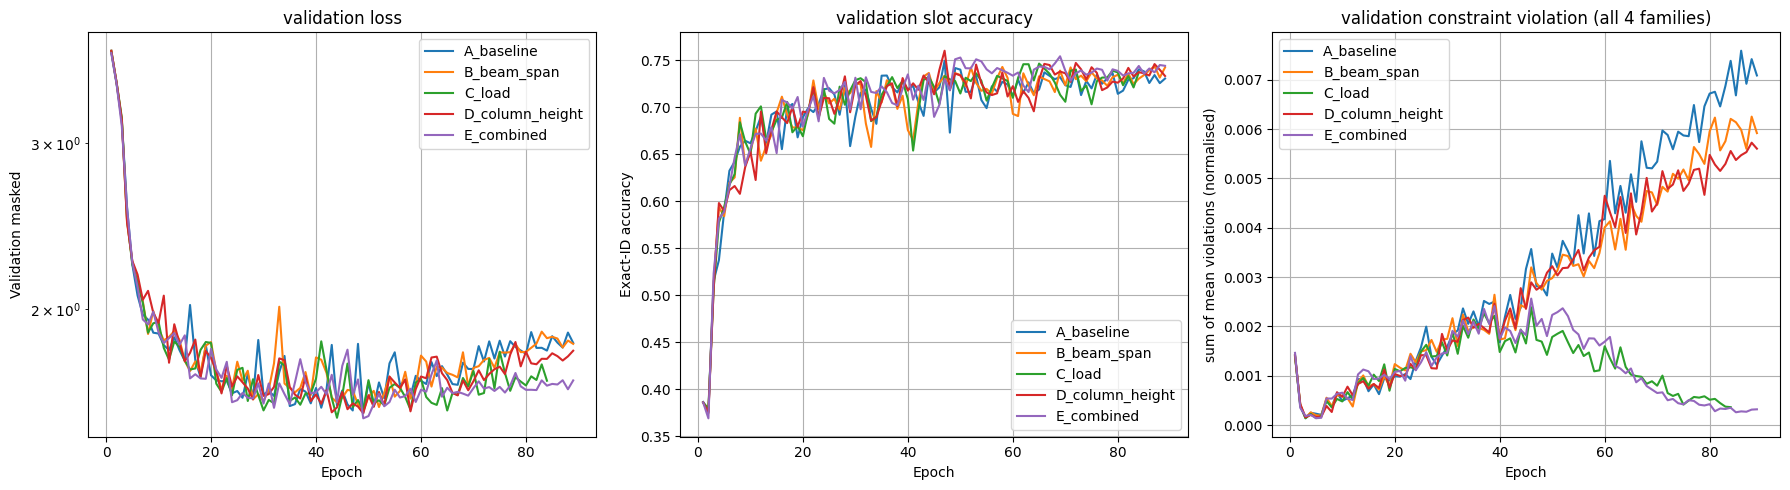

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

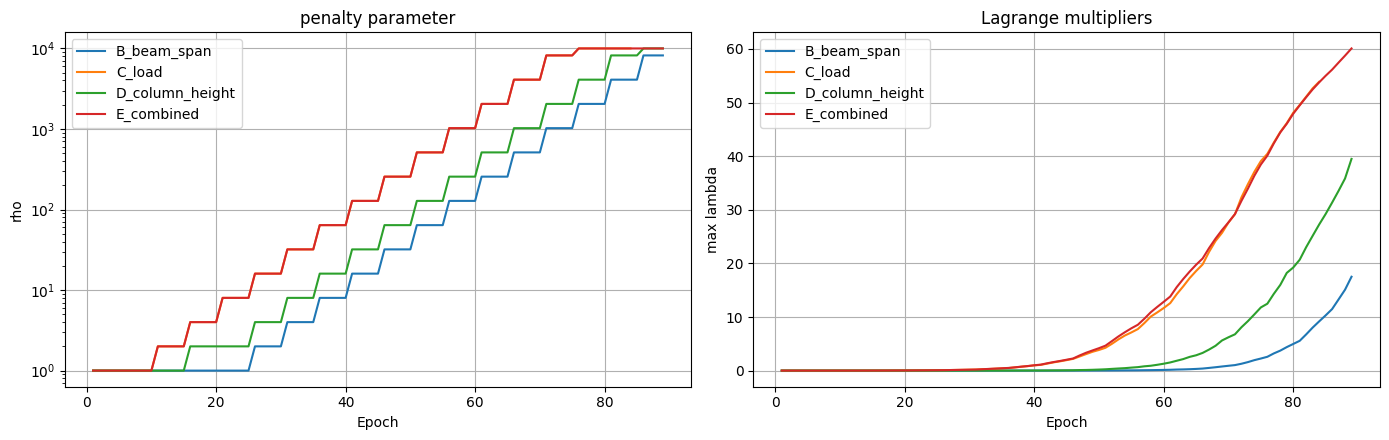

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
from google.colab import files

# ============================================================
# Comparison plots
# ============================================================
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for name, r in RESULTS.items():
    h = r["history"]
    ax[0].plot(h["epoch"], h["validation_loss"], label=name)
    ax[1].plot(h["epoch"], h["validation_slot_accuracy"], label=name)
    ax[2].plot(h["epoch"], sum(h[f"{f}_violation"] for f in FAMILIES), label=name)
ax[0].set(xlabel="Epoch", ylabel="Validation masked", yscale="log", title="validation loss")
ax[1].set(xlabel="Epoch", ylabel="Exact-ID accuracy", title="validation slot accuracy")
ax[2].set(xlabel="Epoch", ylabel="sum of mean violations (normalised)", title="validation constraint violation (all 4 families)")
for a in ax:
    a.grid(True); a.legend()
plt.tight_layout()
comp_path = OUTPUT_DIR / f"{dnn}-alm-comparison.png"
plt.savefig(comp_path, dpi=150, bbox_inches="tight")
plt.show()
files.download(str(comp_path))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, r in RESULTS.items():
    h = r["history"]
    if r["cfg"]["enabled"]:
        ax[0].plot(h["epoch"], h["rho"], label=name); ax[1].plot(h["epoch"], h["lambda_max"], label=name)
ax[0].set(xlabel="Epoch", ylabel="rho", yscale="log", title="penalty parameter"); ax[1].set(xlabel="Epoch", ylabel="max lambda", title="Lagrange multipliers")
for a in ax:
    a.grid(True); a.legend()
plt.tight_layout()
mult_path = OUTPUT_DIR / f"{dnn}-alm-multipliers.png"
plt.savefig(mult_path, dpi=150, bbox_inches="tight")
plt.show()
files.download(str(mult_path))

In [27]:
# # ============================================================
# # Comparison plots
# # ============================================================
# fig, ax = plt.subplots(1, 3, figsize=(18, 5))
# for name, r in RESULTS.items():
#     h = r["history"]
#     ax[0].plot(h["epoch"], h["validation_loss"], label=name)
#     ax[1].plot(h["epoch"], h["validation_slot_accuracy"], label=name)
#     ax[2].plot(h["epoch"], sum(h[f"{f}_violation"] for f in FAMILIES), label=name)
# ax[0].set(xlabel="Epoch", ylabel="Validation masked CE", yscale="log", title="validation loss (CE only)")
# ax[1].set(xlabel="Epoch", ylabel="Exact-ID accuracy", title="validation slot accuracy")
# ax[2].set(xlabel="Epoch", ylabel="sum of mean violations (normalised)", title="validation constraint violation (all 4 families)")
# for a in ax:
#     a.grid(True); a.legend()
# plt.tight_layout(); plt.savefig(OUTPUT_DIR / f"{dnn}-alm-comparison.png", dpi=150, bbox_inches="tight"); plt.show()

# fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
# for name, r in RESULTS.items():
#     h = r["history"]
#     if r["cfg"]["enabled"]:
#         ax[0].plot(h["epoch"], h["rho"], label=name); ax[1].plot(h["epoch"], h["lambda_max"], label=name)
# ax[0].set(xlabel="Epoch", ylabel="rho", yscale="log", title="penalty parameter"); ax[1].set(xlabel="Epoch", ylabel="max lambda", title="Lagrange multipliers")
# for a in ax:
#     a.grid(True); a.legend()
# plt.tight_layout(); plt.savefig(OUTPUT_DIR / f"{dnn}-alm-multipliers.png", dpi=150, bbox_inches="tight"); plt.show()


## Prediction for a new building (inference unchanged)

In [22]:
# Select the model used for inference below. Inference is UNCHANGED: building CSV -> grid -> DNN -> argmax -> catalogue section.
model = RESULTS[FINAL_MODEL_NAME]["model"]
print("Inference model:", FINAL_MODEL_NAME)


Inference model: A_baseline


In [23]:
# Predict a new building from a CSV (building parameters are read from the file contents)
def predict_from_csv(path, save=True):
    b = parse_building(path, need_labels=False)           # section lists are not required here
    X, g = encode_building(b, spec)
    ic, ib = predict_indices(X[None])
    ic, ib = ic[0], ib[0]
    df = results_table(b, g, ic, ib)
    print(f"{os.path.basename(path)}: {b['n_floors']} story, {b['nx']} X-span(s) {b['x_spans']}, "
          f"{b['ny']} Y-span(s) {b['y_spans']}, heights {b['heights']}, load {b['load']} kN/m2")
    for s in range(1, b["n_floors"] + 1):
        show_plan(b, g, ic, ib, s)
    print(f"Estimated steel weight: {total_weight(g, ic, ib):.1f} kg")
    if save:
        out = os.path.join(OUTPUT_DIR, "pred_" + os.path.basename(path))
        df.to_csv(out, index=False, encoding="utf-8-sig")
        print("Saved:", out)
    return df

# Example: predict the first three test buildings (replace with the path of any new building CSV)
for p in sorted(glob.glob(str(DATASET_ROOT / "test" / "*.csv")))[:3]:
    display(predict_from_csv(p).head(30))

F3_X1_4000_Y1_4000_H3500_W6p0_model.csv: 3 story, 1 X-span(s) [4000.0], 1 Y-span(s) [4000.0], heights {3: 3500.0, 2: 3500.0, 1: 3500.0}, load 6.0 kN/m2
--- story 1 (top of story = beam level) ---
Y2 [C  4]--X  7--[C  4]
   |Y7           |Y7           
Y1 [C  4]--X  7--[C  4]
--- story 2 (top of story = beam level) ---
Y2 [C  4]--X  7--[C  4]
   |Y7           |Y7           
Y1 [C  4]--X  7--[C  4]
--- story 3 (top of story = beam level) ---
Y2 [C  3]--X  4--[C  3]
   |Y4           |Y4           
Y1 [C  3]--X  4--[C  3]
Estimated steel weight: 2754.3 kg
Saved: /content/drive/MyDrive/research/dnn8/dnn-alm-results/pred_F3_X1_4000_Y1_4000_H3500_W6p0_model.csv


,story,member,x_line,y_line,x_mm,y_mm,length_mm,catalog_id,section_name,weight_kg
0,1,column,1,1,0.0,0.0,3500.0,4,B-175x175x6x15,108.0415
1,1,beam_X,1,1,0.0,0.0,4000.0,7,H-250x125x6x9x8,116.0840
2,1,beam_Y,1,1,0.0,0.0,4000.0,7,H-250x125x6x9x8,116.0840
3,1,column,2,1,4000.0,0.0,3500.0,4,B-175x175x6x15,108.0415
4,1,beam_Y,2,1,4000.0,0.0,4000.0,7,H-250x125x6x9x8,116.0840
5,1,column,1,2,0.0,4000.0,3500.0,4,B-175x175x6x15,108.0415
6,1,beam_X,1,2,0.0,4000.0,4000.0,7,H-250x125x6x9x8,116.0840
7,1,column,2,2,4000.0,4000.0,3500.0,4,B-175x175x6x15,108.0415
8,2,column,1,1,0.0,0.0,3500.0,4,B-175x175x6x15,108.0415
9,2,beam_X,1,1,0.0,0.0,4000.0,7,H-250x125x6x9x8,116.0840


F3_X1_5000_Y1_4000_H3000_W10p0_model.csv: 3 story, 1 X-span(s) [5000.0], 1 Y-span(s) [4000.0], heights {3: 3000.0, 2: 3000.0, 1: 3000.0}, load 10.0 kN/m2
--- story 1 (top of story = beam level) ---
Y2 [C 13]--X  9--[C 13]
   |Y8           |Y8           
Y1 [C 13]--X  9--[C 13]
--- story 2 (top of story = beam level) ---
Y2 [C  8]--X  9--[C  8]
   |Y8           |Y8           
Y1 [C  8]--X  9--[C  8]
--- story 3 (top of story = beam level) ---
Y2 [C 11]--X 15--[C 11]
   |Y15          |Y15          
Y1 [C 11]--X 15--[C 11]
Estimated steel weight: 4407.1 kg
Saved: /content/drive/MyDrive/research/dnn8/dnn-alm-results/pred_F3_X1_5000_Y1_4000_H3000_W10p0_model.csv


,story,member,x_line,y_line,x_mm,y_mm,length_mm,catalog_id,section_name,weight_kg
0,1,column,1,1,0.0,0.0,3000.0,13,B-250x250x8x20,177.195
1,1,beam_X,1,1,0.0,0.0,5000.0,9,H-350x175x7x11x13,246.925
2,1,beam_Y,1,1,0.0,0.0,4000.0,8,H-300x150x6.5x9x13,146.892
3,1,column,2,1,5000.0,0.0,3000.0,13,B-250x250x8x20,177.195
4,1,beam_Y,2,1,5000.0,0.0,4000.0,8,H-300x150x6.5x9x13,146.892
5,1,column,1,2,0.0,4000.0,3000.0,13,B-250x250x8x20,177.195
6,1,beam_X,1,2,0.0,4000.0,5000.0,9,H-350x175x7x11x13,246.925
7,1,column,2,2,5000.0,4000.0,3000.0,13,B-250x250x8x20,177.195
8,2,column,1,1,0.0,0.0,3000.0,8,B-200x200x8x20,139.515
9,2,beam_X,1,1,0.0,0.0,5000.0,9,H-350x175x7x11x13,246.925


F3_X1_5000_Y1_4000_H3000_W7p0_model.csv: 3 story, 1 X-span(s) [5000.0], 1 Y-span(s) [4000.0], heights {3: 3000.0, 2: 3000.0, 1: 3000.0}, load 7.0 kN/m2
--- story 1 (top of story = beam level) ---
Y2 [C  8]--X  7--[C  8]
   |Y7           |Y7           
Y1 [C  8]--X  7--[C  8]
--- story 2 (top of story = beam level) ---
Y2 [C  8]--X  8--[C  8]
   |Y8           |Y8           
Y1 [C  8]--X  8--[C  8]
--- story 3 (top of story = beam level) ---
Y2 [C  3]--X  4--[C  3]
   |Y14          |Y14          
Y1 [C  3]--X  4--[C  3]
Estimated steel weight: 3222.1 kg
Saved: /content/drive/MyDrive/research/dnn8/dnn-alm-results/pred_F3_X1_5000_Y1_4000_H3000_W7p0_model.csv


,story,member,x_line,y_line,x_mm,y_mm,length_mm,catalog_id,section_name,weight_kg
0,1,column,1,1,0.0,0.0,3000.0,8,B-200x200x8x20,139.515
1,1,beam_X,1,1,0.0,0.0,5000.0,7,H-250x125x6x9x8,145.105
2,1,beam_Y,1,1,0.0,0.0,4000.0,7,H-250x125x6x9x8,116.084
3,1,column,2,1,5000.0,0.0,3000.0,8,B-200x200x8x20,139.515
4,1,beam_Y,2,1,5000.0,0.0,4000.0,7,H-250x125x6x9x8,116.084
5,1,column,1,2,0.0,4000.0,3000.0,8,B-200x200x8x20,139.515
6,1,beam_X,1,2,0.0,4000.0,5000.0,7,H-250x125x6x9x8,145.105
7,1,column,2,2,5000.0,4000.0,3000.0,8,B-200x200x8x20,139.515
8,2,column,1,1,0.0,0.0,3000.0,8,B-200x200x8x20,139.515
9,2,beam_X,1,1,0.0,0.0,5000.0,8,H-300x150x6.5x9x13,183.615
